# Repeat Purchase Prediction (90-Day)
**Assignment pipeline:** I. Data Import & EDA → II. Cleaning & Pre-processing → III. Feature Selection → IV. Model Selection & Assessment → V. Final Output

> Cells marked `====missing work here=====` are not done yet.

---
# I. Data Import & Exploratory Data Analysis (EDA)
## I.1 Data Integration
Load `train.csv` (6,534 historical records) and `test.csv` (986 records), then join the optional `clientes.csv` table using `customer_id`.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from IPython.display import display
from matplotlib.ticker import StrMethodFormatter

DATA_DIR = "../data"

fixed_train = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
test = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))
clients = pd.read_csv(os.path.join(DATA_DIR, "clientes.csv"))
train = fixed_train.copy()
print(f"train shape: {train.shape}")
print(f"test shape: {test.shape}")
print(f"clients shape: {clients.shape}")

train shape: (6534, 39)
test shape: (986, 38)
clients shape: (1143, 13)


In [237]:
train.head(5)

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,repeat_purchase_90d,days_since_previous_purchase,customer_tenure_days,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_mean_gap_days,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise
0,558.11,510.90,453.75,104.36,0.0,0.0,57.15,153.099911,4.0,1.0,1,79.0,126.0,2.0,858.30,429.150000,112.656252,349.49,508.81,47.000000,NaN,0.0,0.00,1.0,349.49,2.0,858.30,2.0,858.30,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,10000000,-0.660448
1,978.80,830.02,795.77,183.03,0.0,0.0,34.25,472.943134,32.0,1.0,1,244.0,616.0,5.0,6722.83,1344.566000,1683.795178,84.38,4222.15,93.000000,117.657696,0.0,0.00,0.0,0.00,0.0,0.00,4.0,2500.68,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,10000001,0.924510
2,10.33,12.00,8.40,1.93,0.0,0.0,3.60,6.097485,1.0,1.0,1,9.0,610.0,90.0,17590.08,195.445333,190.389932,4.54,1002.15,6.752809,6.384073,2.0,111.27,9.0,1928.55,28.0,5290.25,49.0,7899.80,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,10000002,-0.258730
3,856.83,696.61,696.61,160.22,0.0,0.0,0.00,408.167275,9.0,1.0,0,97.0,97.0,1.0,270.33,270.330000,NaN,270.33,270.33,NaN,NaN,0.0,0.00,0.0,0.00,1.0,270.33,1.0,270.33,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,10000003,1.448402
4,1616.10,1488.85,1313.90,302.20,0.0,0.0,174.95,485.401864,33.0,1.0,1,85.0,1575.0,25.0,12803.02,512.120800,406.696963,22.58,1736.74,62.083333,66.246520,0.0,0.00,2.0,184.13,4.0,2062.50,4.0,2062.50,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,10000004,-1.058890


In [238]:
clients.head(5)

,customer_id,country_or_region,commercial_region,island,municipality,city,postal_area,postal_code,street,address,customer_type,company_name,customer_since_year
0,842570,Country CT11: Land of The Final Version,Region RG37: We Will See Later,NaN,NaN,City CY417: Missing Cell Port,NaN,Postal code PC828: #REF! Delivery Route,NaN,Address AD1120: Cell Without a Home,NaN,Excel Is Not A Database Ltd 150,2018
1,770941,Country CT9: Land of The Final Version,NaN,NaN,NaN,NaN,NaN,Postal code PC56: #REF! Delivery Route,NaN,Address AD62: Cell Without a Home,NaN,Excel Is Not A Database Ltd 1064,2021
2,827053,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC827: #REF! Delivery Route,Street ST170: PowerPoint New Walk,Address AD449: Cell Without a Home,NaN,Excel Is Not A Database Ltd 113,2016
3,494648,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD454: Cell Without a Home,NaN,Excel Is Not A Database Ltd 430,2015
4,429291,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD453: Cell Without a Home,NaN,Excel Is Not A Database Ltd 673,2015


In [239]:
print(f"===Train dataset Features ({len(train.columns)-1} Features)===")
for i in range(0, len(train.columns), 3):
    print(train.columns[i:i+3].tolist())
print(f"===Client dataset Features ({len(clients.columns)} Features)===")
for i in range(0, len(clients.columns), 3):
    print(clients.columns[i:i+3].tolist())

===Train dataset Features (38 Features)===
['Total a Pagar', 'Total Bruto', 'Total Liquido']
['Total Imp_', 'Total Portes', 'Total Desc_ Global']
['Total Desc_ Linha', 'Custo', 'N_ Detalhes']
['invoice_count_current_purchase', 'repeat_purchase_90d', 'days_since_previous_purchase']
['customer_tenure_days', 'prior_purchase_count', 'prior_total_spend']
['prior_mean_purchase_value', 'prior_std_purchase_value', 'prior_min_purchase_value']
['prior_max_purchase_value', 'prior_mean_gap_days', 'prior_std_gap_days']
['purchase_count_30d', 'spend_30d', 'purchase_count_90d']
['spend_90d', 'purchase_count_180d', 'spend_180d']
['purchase_count_365d', 'spend_365d', 'customer_id']
['payment_type', 'salesperson', 'commercial_zone']
['transport_method', 'warehouse', 'document_series']
['purchase_date', 'ID', 'random_noise']
===Client dataset Features (13 Features)===
['customer_id', 'country_or_region', 'commercial_region']
['island', 'municipality', 'city']
['postal_area', 'postal_code', 'street']
['ad

In [240]:
# Merge clients into train on customer_id
train = train.merge(clients, on='customer_id', how='left')

## I.2 Exploration: Descriptive Statistics
### Target distribution
The goal is binary classification:
- **1**: yes, the customer is expected to buy in the next 90 days
- **0**: no, the customer is not expected to buy in the next 90 days

In [241]:
labelcount = train['repeat_purchase_90d'].value_counts().sort_index()
class0_percentage = labelcount[0]/(labelcount[0]+labelcount[1])
class1_percentage = labelcount[1]/(labelcount[0]+labelcount[1])
print(f"{labelcount}")
print(f"class 0 proportion {class0_percentage*100:.2f} %")
print(f"class 1 proportion {class1_percentage*100:.2f} %")

repeat_purchase_90d
0    2880
1    3654
Name: count, dtype: int64
class 0 proportion 44.08 %
class 1 proportion 55.92 %


Pretty balanced classes.

### Data understanding
**Current Purchase and Invoice Features**
The `Total Bruto` (Gross Total), `Total Liquido` (Net Total), and `Total a Pagar` (Total Amount Due) fields describe the purchase amount at different stages. `Total Imp_` is tax, `Total Portes` is shipping, and `Total Desc_ Global` and `Total Desc_ Linha` are discounts applied to the whole invoice and to individual lines. `Custo` records cost. `N_ Detalhes` counts invoice detail lines, while `invoice_count_current_purchase` counts invoices associated with the current purchase.

**Customer Purchase History**
`prior_purchase_count` and `prior_total_spend` summarize how many purchases the customer made before and how much they spent in total. The `prior_*_purchase_value` features summarize the values of those earlier purchases using the mean, standard deviation, minimum, and maximum.

**Purchase Timing**
`customer_tenure_days` is how long the customer has been in the records. `days_since_previous_purchase` measures the time since their last purchase; `prior_mean_gap_days` and `prior_std_gap_days` summarize the average time between earlier purchases and how much that gap varied.

**Rolling Purchase Features**
The `purchase_count_*` features count how many purchases a customer made within the matching 30-, 90-, 180-, or 365-day look-back window. The corresponding `spend_*` features add up the customer's spending over that same window.

**Random Noise**
`random_noise` appears to be a randomly generated numeric feature rather than a meaningful customer or purchase measure.

### Categorical / numerical split
We are not excluding the clients dataset here, just viewing feature data cleanliness.

In [242]:
train.dtypes

Total a Pagar                     float64
Total Bruto                       float64
Total Liquido                     float64
Total Imp_                        float64
Total Portes                      float64
Total Desc_ Global                float64
Total Desc_ Linha                 float64
Custo                             float64
N_ Detalhes                       float64
invoice_count_current_purchase    float64
repeat_purchase_90d                 int64
days_since_previous_purchase      float64
customer_tenure_days              float64
prior_purchase_count              float64
prior_total_spend                 float64
prior_mean_purchase_value         float64
prior_std_purchase_value          float64
prior_min_purchase_value          float64
prior_max_purchase_value          float64
prior_mean_gap_days               float64
prior_std_gap_days                float64
purchase_count_30d                float64
spend_30d                         float64
purchase_count_90d                

In [243]:
categorical_cols = (
    train.select_dtypes(include=["object", "category", "string"])
         .columns.drop("purchase_date", errors="ignore")
         .tolist()
)

categorical_train = train[categorical_cols]
print(categorical_train.head(1))

# Check for missing values
categorical_null_counts = categorical_train.isna().sum()
categorical_null_counts = categorical_null_counts[categorical_null_counts > 0]

if categorical_null_counts.empty:
    print("No missing values in categorical features.")
else:
    print("Categorical features with missing values:")
    print(categorical_null_counts.sort_values(ascending=False))

                payment_type       salesperson              commercial_zone  \
0  Maybe Tomorrow Payment 10  VLOOKUP Master 9  Decorative Dashboard Zone 4   

             transport_method                warehouse  document_series  \
0  Maybe Tomorrow Delivery 61  Final Excel Warehouse 1  Ctrl Z Series 2   

                         country_or_region               commercial_region  \
0  Country CT10: Land of The Final Version  Region RG25: We Will See Later   

  island                                     municipality  \
0    NaN  Municipality MU89: Council of Last Minute Edits   

                              city                             postal_area  \
0  City CY286: Cached Result Falls  Postal area PA228: Hidden Sheet Sector   

                               postal_code  \
0  Postal code PC444: #REF! Delivery Route   

                                     street  \
0  Street ST303: Absolute Reference Terrace   

                              address                      compan

### Numerical feature summary (raw, before cleaning)

In [244]:
target = "repeat_purchase_90d"
exclude = [target, "customer_id", "ID"]

numerical_cols = (
    train.select_dtypes(include="number")
         .columns.drop(exclude, errors="ignore")
         .tolist()
)

numerical_train = train[numerical_cols]
numerical_summary = numerical_train.describe().T.rename(
    columns={"50%": "median"}
)
numerical_summary["missing"] = numerical_train.isna().sum()
numerical_summary["IQR"] = numerical_summary["75%"] - numerical_summary["25%"]
numerical_summary = numerical_summary[
    ["count", "missing", "mean", "std", "min", "25%", "median", "75%", "max", "IQR"]
]
print(numerical_summary.to_string(float_format=lambda value: f"{value:,.2f}"))

right_skew = [c for c in numerical_cols if numerical_train[c].skew() > 1]
left_skew = [c for c in numerical_cols if numerical_train[c].skew() < -1]
print(f"\n{len(right_skew)} right-skewed (skew > 1): {right_skew}")
print(f"{len(left_skew)} left-skewed  (skew < -1): {left_skew}")

                                  count  missing         mean           std         min      25%   median       75%              max       IQR
Total a Pagar                  6,469.00       65       925.56      1,335.00        0.93   188.92   476.74  1,087.67        22,297.21    898.75
Total Bruto                    6,469.00       65       886.15      1,327.64        0.83   175.74   445.74  1,036.70        21,578.28    860.96
Total Liquido                  6,469.00       65       773.34      1,136.36        0.76   154.38   389.91    903.37        18,127.81    748.99
Total Imp_                     6,469.00       65       152.22        225.26        0.00    29.93    79.74    184.84         4,169.40    154.91
Total Portes                   6,469.00       65         1.15          5.84        0.00     0.00     0.00      0.00           181.06      0.00
Total Desc_ Global             6,469.00       65         0.35          5.12        0.00     0.00     0.00      0.00           218.49      0.00

## I.3 Relationship Mapping
### Univariate analysis vs. `repeat_purchase_90d`
> Note: these run on the merged but **not yet cleaned** data. Cleaning is in Section II.

#### Categorical features (train)

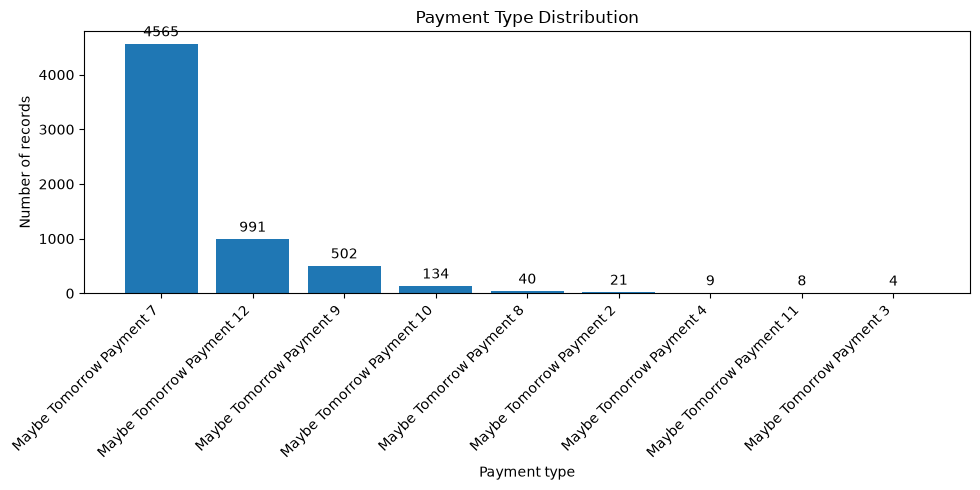

In [245]:
payment_type = categorical_train["payment_type"]
payment_counts = payment_type.value_counts()

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(payment_counts.index, payment_counts.values)

ax.set_title("Payment Type Distribution")
ax.set_xlabel("Payment type")
ax.set_ylabel("Number of records")
ax.tick_params(axis="x", labelrotation=45)
plt.setp(ax.get_xticklabels(), ha="right")
ax.bar_label(ax.containers[0], padding=3)

fig.tight_layout()
plt.show()

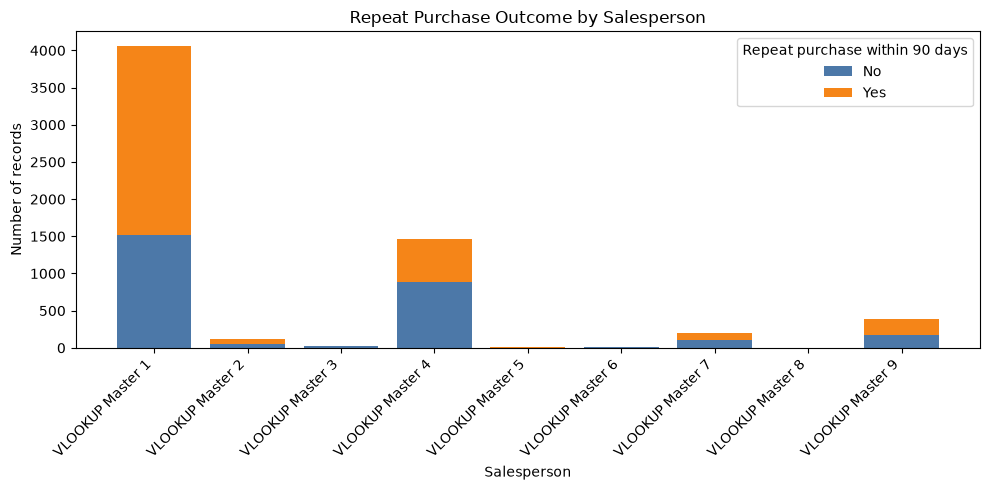

In [246]:
salesperson_target_counts = pd.crosstab(
    train["salesperson"], train["repeat_purchase_90d"]
).reindex(columns=[0, 1], fill_value=0)

x = np.arange(len(salesperson_target_counts))
no_counts = salesperson_target_counts[0]
yes_counts = salesperson_target_counts[1]

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x, no_counts, label="No", color="#4C78A8")
ax.bar(x, yes_counts, bottom=no_counts, label="Yes", color="#F58518")

ax.set_title("Repeat Purchase Outcome by Salesperson")
ax.set_xlabel("Salesperson")
ax.set_ylabel("Number of records")
ax.set_xticks(x, salesperson_target_counts.index, rotation=45, ha="right")
ax.legend(title="Repeat purchase within 90 days")

fig.tight_layout()
plt.show()

The salesperson might affect the label (logically meaningful, but not statistically proven yet).

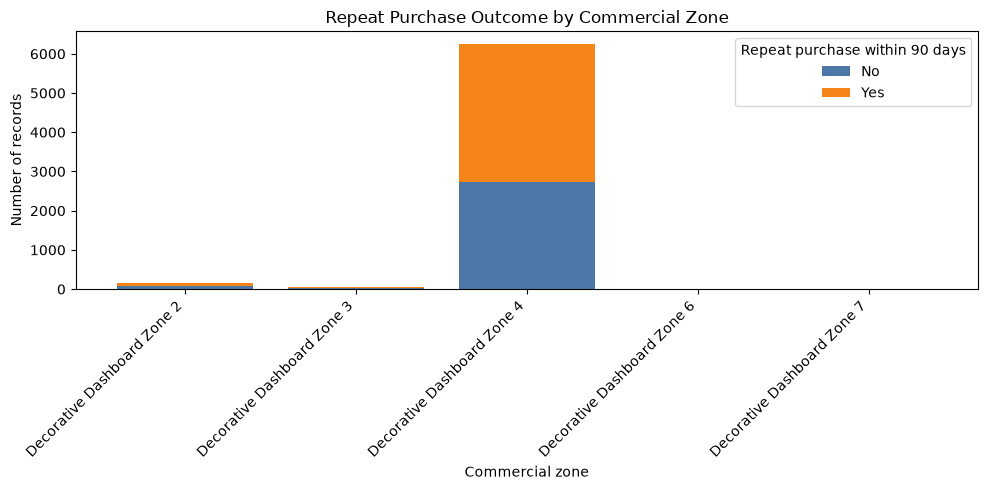

In [247]:
commercial_zone_target_counts = pd.crosstab(
    train["commercial_zone"], train["repeat_purchase_90d"]
).reindex(columns=[0, 1], fill_value=0)

x = np.arange(len(commercial_zone_target_counts))
no_counts = commercial_zone_target_counts[0]
yes_counts = commercial_zone_target_counts[1]

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x, no_counts, label="No", color="#4C78A8")
ax.bar(x, yes_counts, bottom=no_counts, label="Yes", color="#F58518")

ax.set_title("Repeat Purchase Outcome by Commercial Zone")
ax.set_xlabel("Commercial zone")
ax.set_ylabel("Number of records")
ax.set_xticks(x, commercial_zone_target_counts.index, rotation=45, ha="right")
ax.legend(title="Repeat purchase within 90 days")

fig.tight_layout()
plt.show()

**`commercial_zone` has a highly skewed category distribution: nearly all non-missing observations are in Zone 4, with very few in the other zones.**

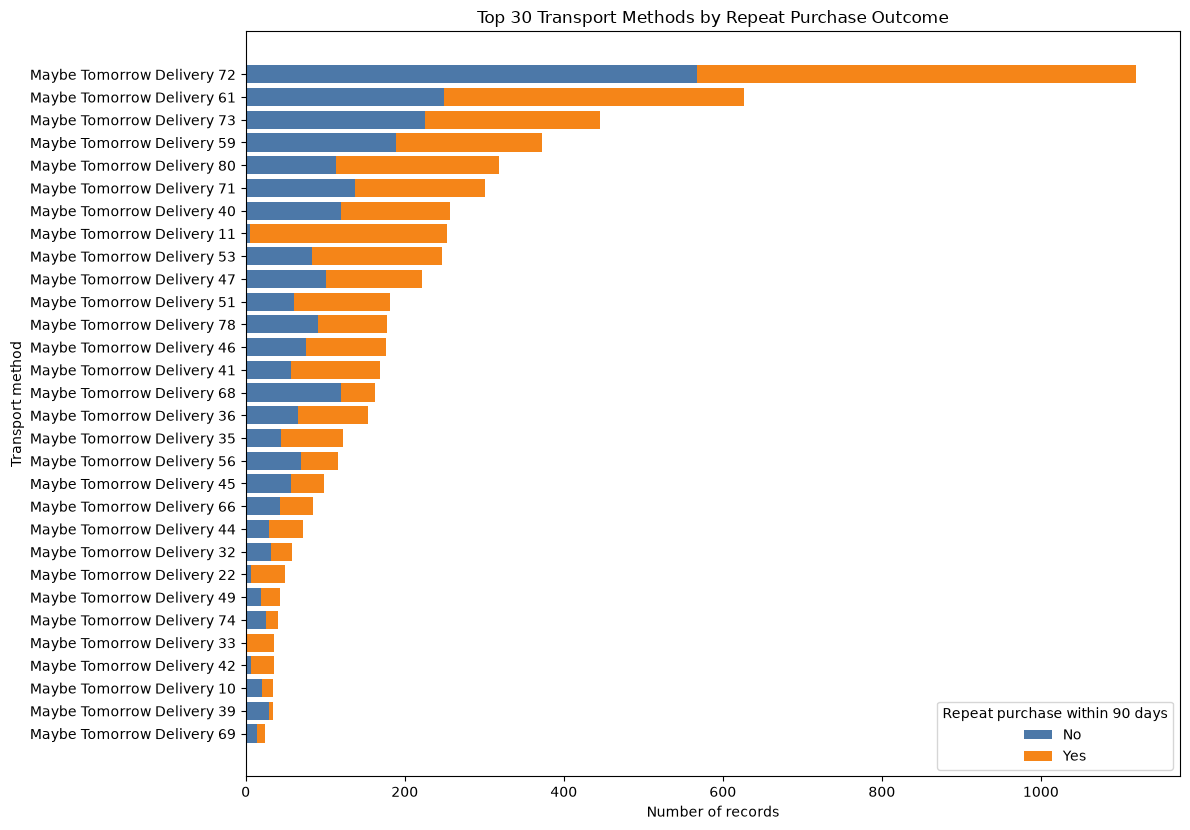

In [248]:
transport_method_target_counts = pd.crosstab(
    train["transport_method"], train["repeat_purchase_90d"]
).reindex(columns=[0, 1], fill_value=0)
transport_method_target_counts = transport_method_target_counts.loc[
    transport_method_target_counts.sum(axis=1).nlargest(30).index
]

y = np.arange(len(transport_method_target_counts))
no_counts = transport_method_target_counts[0]
yes_counts = transport_method_target_counts[1]

fig, ax = plt.subplots(
    figsize=(12, max(7, len(transport_method_target_counts) * 0.28))
)
ax.barh(y, no_counts, label="No", color="#4C78A8")
ax.barh(y, yes_counts, left=no_counts, label="Yes", color="#F58518")

ax.set_title("Top 30 Transport Methods by Repeat Purchase Outcome")
ax.set_xlabel("Number of records")
ax.set_ylabel("Transport method")
ax.set_yticks(y, transport_method_target_counts.index)
ax.invert_yaxis()
ax.legend(title="Repeat purchase within 90 days")

fig.tight_layout()
plt.show()

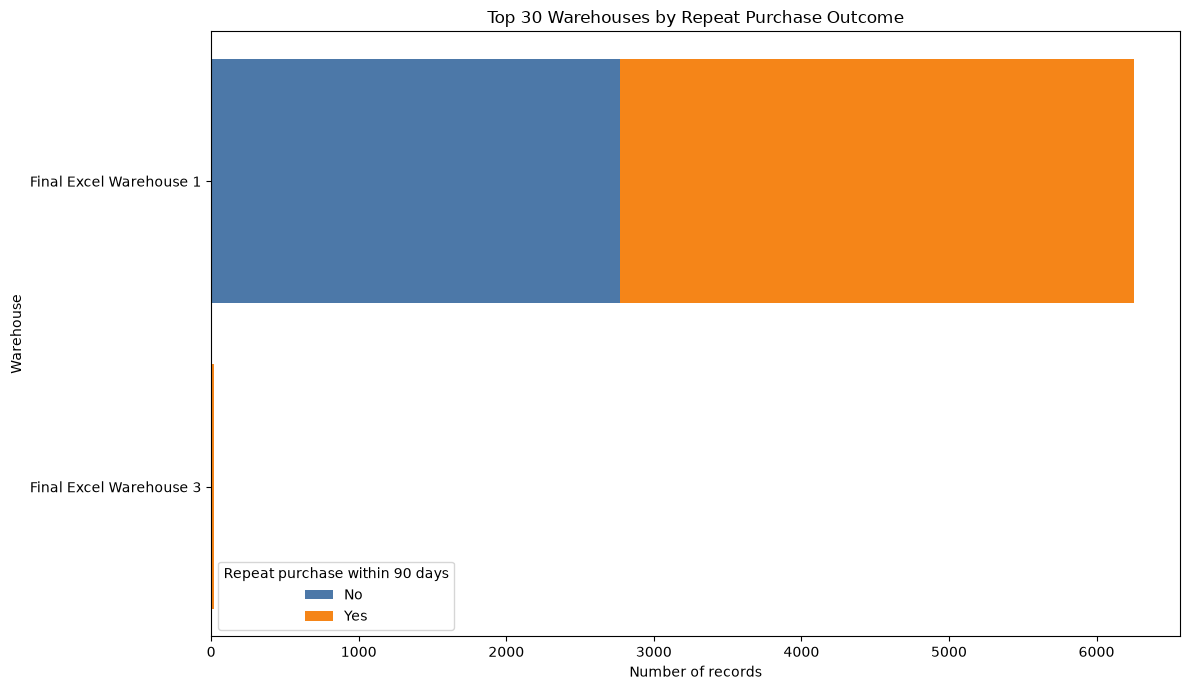

In [249]:
warehouse_target_counts = pd.crosstab(
    train["warehouse"], train["repeat_purchase_90d"]
).reindex(columns=[0, 1], fill_value=0)
warehouse_target_counts = warehouse_target_counts.loc[
    warehouse_target_counts.sum(axis=1).nlargest(30).index
]

y = np.arange(len(warehouse_target_counts))
no_counts = warehouse_target_counts[0]
yes_counts = warehouse_target_counts[1]

fig, ax = plt.subplots(
    figsize=(12, max(7, len(warehouse_target_counts) * 0.28))
)
ax.barh(y, no_counts, label="No", color="#4C78A8")
ax.barh(y, yes_counts, left=no_counts, label="Yes", color="#F58518")

ax.set_title("Top 30 Warehouses by Repeat Purchase Outcome")
ax.set_xlabel("Number of records")
ax.set_ylabel("Warehouse")
ax.set_yticks(y, warehouse_target_counts.index)
ax.invert_yaxis()
ax.legend(title="Repeat purchase within 90 days")

fig.tight_layout()
plt.show()

`warehouse` should probably be discarded: nearly all records are Warehouse 1, and Warehouse 3 is too small to learn patterns from.

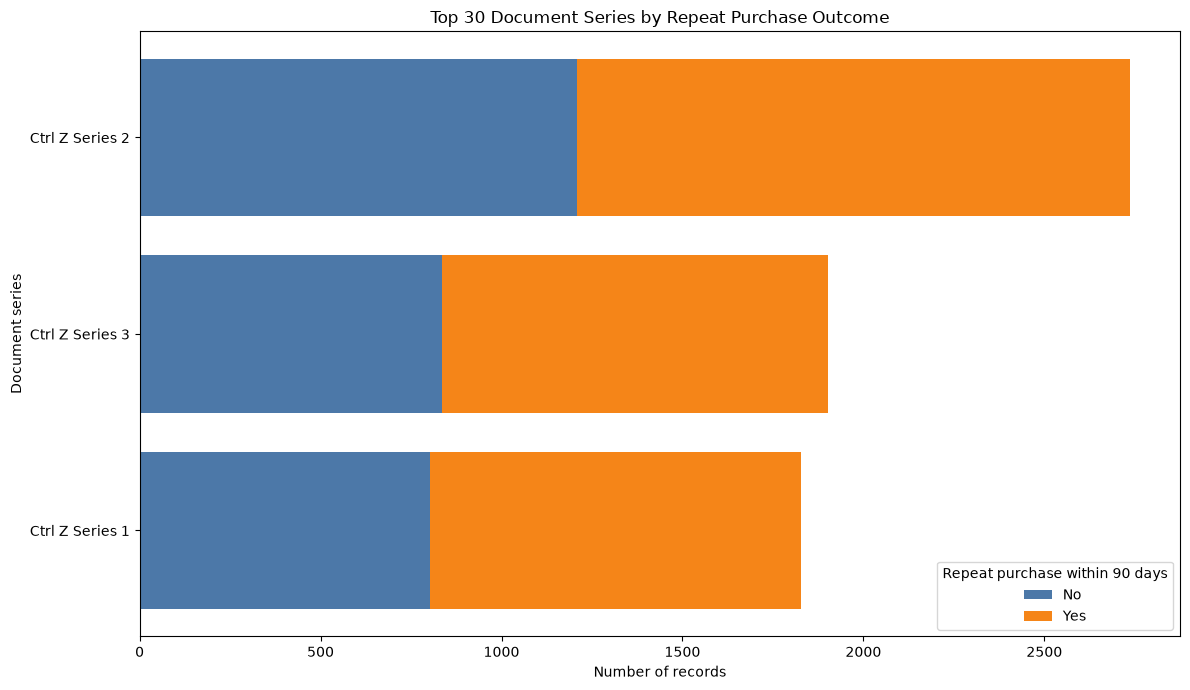

In [250]:
document_series_target_counts = pd.crosstab(
    train["document_series"], train["repeat_purchase_90d"]
).reindex(columns=[0, 1], fill_value=0)
document_series_target_counts = document_series_target_counts.loc[
    document_series_target_counts.sum(axis=1).nlargest(30).index
]

y = np.arange(len(document_series_target_counts))
no_counts = document_series_target_counts[0]
yes_counts = document_series_target_counts[1]

fig, ax = plt.subplots(
    figsize=(12, max(7, len(document_series_target_counts) * 0.28))
)
ax.barh(y, no_counts, label="No", color="#4C78A8")
ax.barh(y, yes_counts, left=no_counts, label="Yes", color="#F58518")

ax.set_title("Top 30 Document Series by Repeat Purchase Outcome")
ax.set_xlabel("Number of records")
ax.set_ylabel("Document series")
ax.set_yticks(y, document_series_target_counts.index)
ax.invert_yaxis()
ax.legend(title="Repeat purchase within 90 days")

fig.tight_layout()
plt.show()

#### Client features (from `clientes.csv`)

Clients dataset shape: (1143, 13)

Client dataset preview:


,customer_id,country_or_region,commercial_region,island,municipality,city,postal_area,postal_code,street,address,customer_type,company_name,customer_since_year
0,842570,Country CT11: Land of The Final Version,Region RG37: We Will See Later,NaN,NaN,City CY417: Missing Cell Port,NaN,Postal code PC828: #REF! Delivery Route,NaN,Address AD1120: Cell Without a Home,NaN,Excel Is Not A Database Ltd 150,2018
1,770941,Country CT9: Land of The Final Version,NaN,NaN,NaN,NaN,NaN,Postal code PC56: #REF! Delivery Route,NaN,Address AD62: Cell Without a Home,NaN,Excel Is Not A Database Ltd 1064,2021
2,827053,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC827: #REF! Delivery Route,Street ST170: PowerPoint New Walk,Address AD449: Cell Without a Home,NaN,Excel Is Not A Database Ltd 113,2016
3,494648,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD454: Cell Without a Home,NaN,Excel Is Not A Database Ltd 430,2015
4,429291,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD453: Cell Without a Home,NaN,Excel Is Not A Database Ltd 673,2015



NaN values per client feature:
customer_type          1143
street                  598
island                  578
city                    546
postal_code             170
municipality            159
commercial_region       114
postal_area              71
address                   6
customer_id               0
country_or_region         0
company_name              0
customer_since_year       0

Client numerical feature summary:
                       count  missing     mean  std      min      25%   median      75%      max  IQR
customer_since_year 1,143.00        0 2,017.00 2.97 2,015.00 2,015.00 2,015.00 2,018.00 2,026.00 3.00
Joined shape: (6534, 51)
Rows matched to a client: 6,534 / 6,534

Repeat-purchase rate by common client categories (minimum 30 records):
          feature                                        category  records repeat_rate
country_or_region         Country CT10: Land of The Final Version     6321       56.5%
country_or_region          Country CT5: Land of The Fi

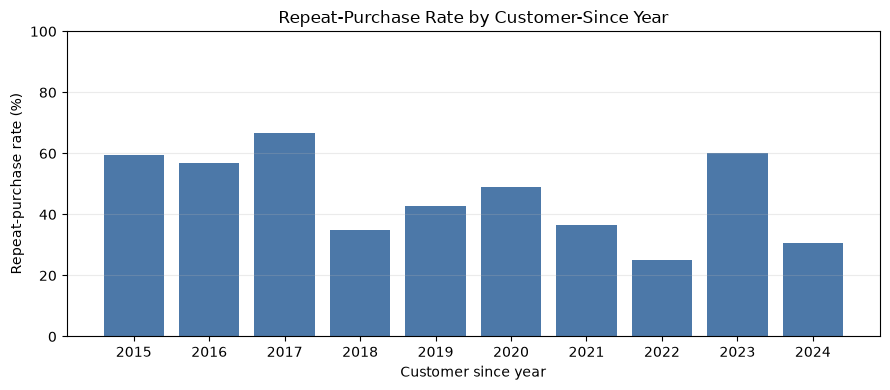

In [251]:
print("Clients dataset shape:", clients.shape)
print("\nClient dataset preview:")
display(clients.head())

client_missing_counts = clients.isna().sum().sort_values(ascending=False)
print("\nNaN values per client feature:")
print(client_missing_counts.to_string())

client_numeric_cols = [
    column for column in clients.select_dtypes(include="number").columns
    if column != "customer_id" and clients[column].notna().any()
]
client_numerical = clients[client_numeric_cols]
client_summary = client_numerical.describe().T.rename(
    columns={"50%": "median"}
)
client_summary["missing"] = client_numerical.isna().sum()
client_summary["IQR"] = client_summary["75%"] - client_summary["25%"]
client_summary = client_summary[
    ["count", "missing", "mean", "std", "min", "25%", "median", "75%", "max", "IQR"]
]
print("\nClient numerical feature summary:")
print(client_summary.to_string(float_format=lambda value: f"{value:,.2f}"))

matched_clients = train["country_or_region"].notna().sum()
print(f"Joined shape: {train.shape}")
print(f"Rows matched to a client: {matched_clients:,} / {len(train):,}")

client_categorical_features = [
    column for column in clients.select_dtypes(include=["object", "category", "string"]).columns
    if clients[column].notna().any() and column in train.columns
]
minimum_category_rows = 30
maximum_categories = 5
relationship_tables = []

for feature in client_categorical_features:
    categories = train[feature].astype("string").fillna("Missing")
    common_categories = categories.value_counts()
    common_categories = common_categories[common_categories >= minimum_category_rows]
    common_categories = common_categories.head(maximum_categories).index
    grouped_categories = categories.where(categories.isin(common_categories), "Other / rare")
    feature_summary = (
        pd.DataFrame({"category": grouped_categories,
                      "repeat_purchase_90d": train[target]})
        .groupby("category")["repeat_purchase_90d"]
        .agg(records="size", repeat_rate="mean")
        .reset_index()
    )
    feature_summary.insert(0, "feature", feature)
    relationship_tables.append(feature_summary)

client_category_relationships = pd.concat(relationship_tables, ignore_index=True)
client_category_relationships["repeat_rate"] *= 100
print("\nRepeat-purchase rate by common client categories (minimum 30 records):")
print(client_category_relationships.to_string(
    index=False,
    formatters={"repeat_rate": "{:.1f}%".format},
))

year_summary = (
    train.groupby("customer_since_year")["repeat_purchase_90d"]
    .agg(records="size", repeat_rate="mean")
)
year_summary["repeat_rate"] *= 100
print("\nRepeat-purchase rate by customer-since year:")
print(year_summary.to_string(formatters={"repeat_rate": "{:.1f}%".format}))

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(year_summary.index.astype(str), year_summary["repeat_rate"], color="#4C78A8")
ax.set_title("Repeat-Purchase Rate by Customer-Since Year")
ax.set_xlabel("Customer since year")
ax.set_ylabel("Repeat-purchase rate (%)")
ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

The bars show the **observed repeat-purchase rate** for each country or region:

$$\text{repeat rate} = \frac{\text{customers with repeat\_purchase\_90d = 1}}{\text{customers in that group}} \times 100$$

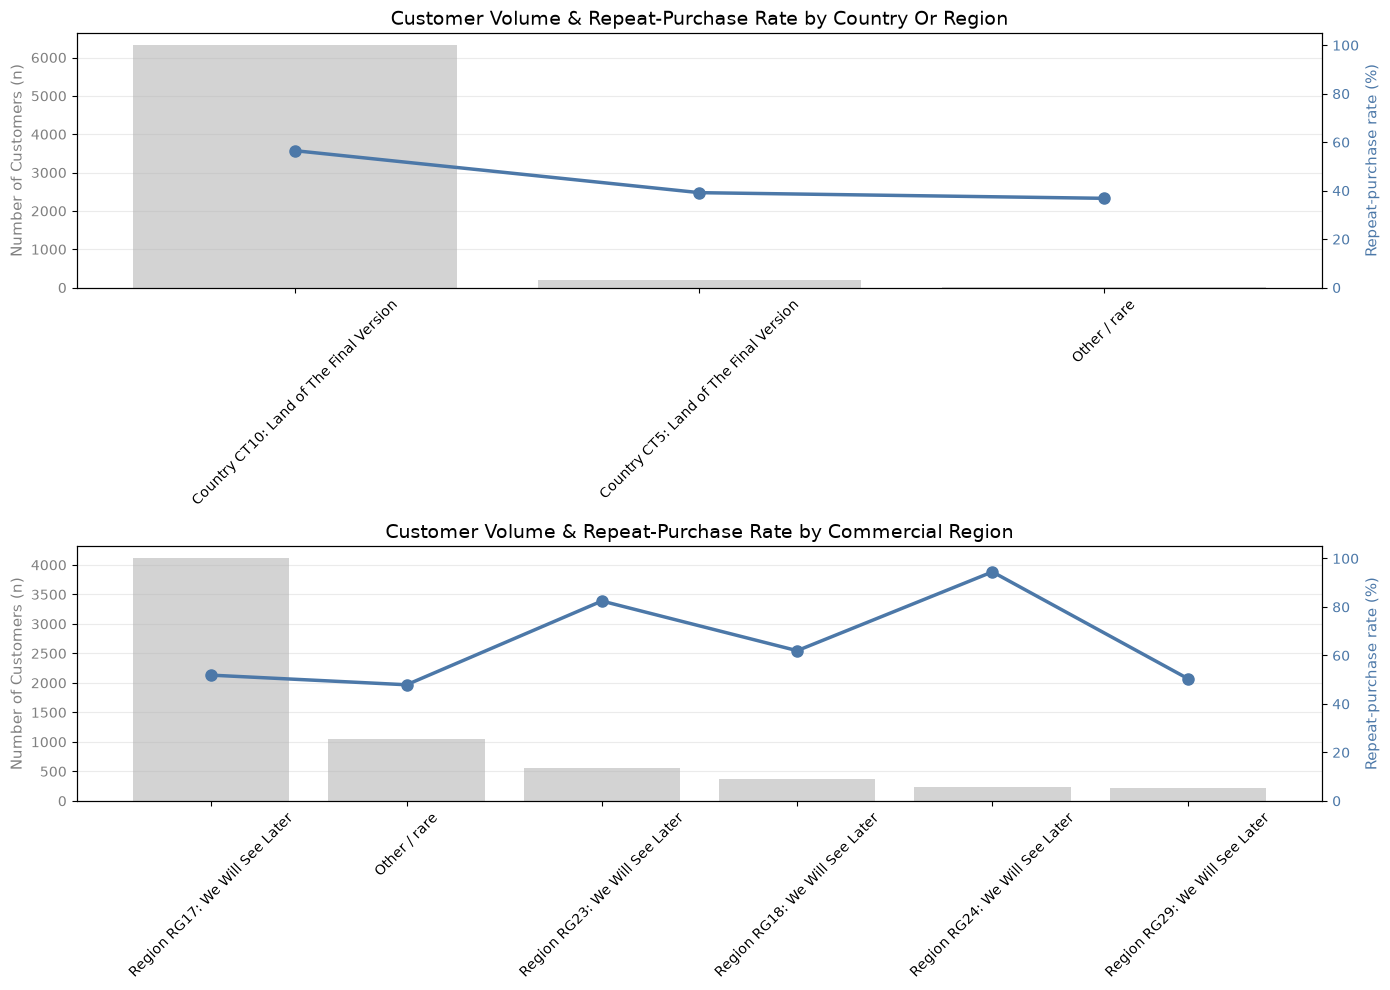

In [252]:
location_features = ["country_or_region", "commercial_region"]
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

for ax1, feature in zip(axes, location_features):
    summary = client_category_relationships[
        client_category_relationships["feature"] == feature
    ].sort_values("records", ascending=False)

    categories = summary["category"]
    records = summary["records"]
    rates = summary["repeat_rate"]

    # 1st axis: number of customers (bars)
    ax1.bar(categories, records, color="#d3d3d3", label="Number of Customers")
    ax1.set_ylabel("Number of Customers (n)", color="gray", fontsize=11)
    ax1.tick_params(axis='y', labelcolor="gray")
    ax1.tick_params(axis='x', rotation=45)
    ax1.grid(axis="y", alpha=0.25)

    # 2nd axis: repeat rate (line)
    ax2 = ax1.twinx()
    ax2.plot(categories, rates, color="#4C78A8", marker='o', linewidth=2.5, markersize=8, label="Repeat Rate (%)")
    ax2.set_ylabel("Repeat-purchase rate (%)", color="#4C78A8", fontsize=11)
    ax2.set_ylim(0, 105)
    ax2.tick_params(axis='y', labelcolor="#4C78A8")

    ax1.set_title(f"Customer Volume & Repeat-Purchase Rate by {feature.replace('_', ' ').title()}", fontsize=14)

fig.tight_layout()
plt.show()

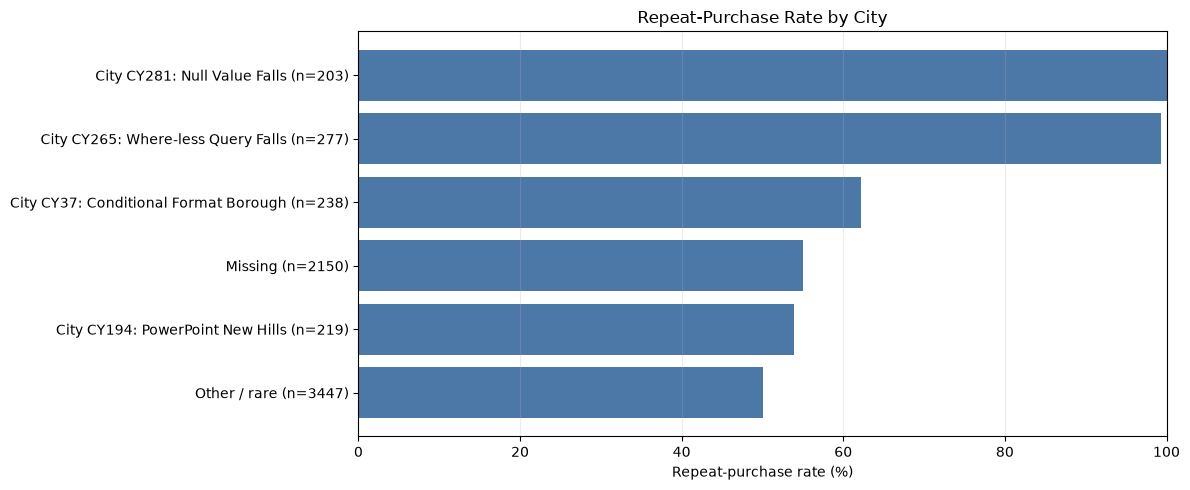


Distinct customers by city group (repeat_purchase_90d = 1 at least once):
                                       customers  repeat_buyers
city_group                                                     
Other / rare                                 352            207
City CY194: PowerPoint New Hills              11              9
Missing                                      236            126
City CY37: Conditional Format Borough          9              8
City CY265: Where-less Query Falls             1              1
City CY281: Null Value Falls                   1              1


In [253]:
city_summary = client_category_relationships[
    client_category_relationships["feature"] == "city"
].sort_values("repeat_rate")
city_labels = [
    f"{category} (n={records})"
    for category, records in zip(city_summary["category"], city_summary["records"])
]

fig, ax = plt.subplots(figsize=(12, 5))
ax.barh(city_labels, city_summary["repeat_rate"], color="#4C78A8")
ax.set_title("Repeat-Purchase Rate by City")
ax.set_xlabel("Repeat-purchase rate (%)")
ax.set_xlim(0, 100)
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

# Count each customer once, even if they have multiple positive training rows.
city_row_values = train["city"].astype("string").fillna("Missing")
common_city_categories = city_row_values.value_counts()
common_city_categories = common_city_categories[
    common_city_categories >= minimum_category_rows
].head(maximum_categories).index
customer_repeat_status = (
    fixed_train.groupby("customer_id")[target]
    .max()
    .rename("repeat_buyer")
    .reset_index()
)
buyers_by_city = clients[["customer_id", "city"]].merge(
    customer_repeat_status,
    on="customer_id",
    how="inner",
    validate="one_to_one",
)
buyer_city_values = buyers_by_city["city"].astype("string").fillna("Missing")
buyers_by_city["city_group"] = buyer_city_values.where(
    buyer_city_values.isin(common_city_categories), "Other / rare"
)
city_customer_counts = buyers_by_city.groupby("city_group").agg(
    customers=("customer_id", "nunique"),
    repeat_buyers=("repeat_buyer", "sum"),
).reindex(city_summary["category"], fill_value=0).astype(int)
city_customer_counts.index.name = "city_group"
print("\nDistinct customers by city group (repeat_purchase_90d = 1 at least once):")
print(city_customer_counts.to_string())

**Caution:** City CY281's 100% rate comes from 203 records for just one customer, not 203 different customers. It does not mean customers in that city always repeat. **This observation can be misleading.**

### Multivariate analysis
Correlation analysis (Spearman / Pearson) needs cleaned data, so the active version is in **Section III (Filter Methods, Numerical vs. Numerical)**. The earlier version on uncleaned data is kept below for reference.

In [254]:
# # unclean data
# correlation_data = fixed_train.merge(
#     clients,
#     on="customer_id",
#     how="left",
#     validate="many_to_one",
# )
# excluded_features = ["ID", "customer_id", "random_noise"]
# numeric_features = correlation_data.select_dtypes(include="number").drop(
#     columns=excluded_features, errors="ignore"
# )
# numeric_features = numeric_features.loc[
#     :, numeric_features.nunique(dropna=True) > 1
# ]
# corr_matrix = numeric_features.corr()
#
# plt.figure(figsize=(14, 12))
# sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, linewidths=0.5)
# plt.title("Correlation Matrix of Numeric Transaction and Client Features")
# plt.tight_layout()
# plt.show()
#
# print(corr_matrix["repeat_purchase_90d"].sort_values(ascending=False))

---
# II. Data Cleaning & Pre-processing
## II.1 Missing & Anomalous Data
We improve data quality by removing unexplainable entries and dropping irrelevant features (identifiers).

### Illogical / too-corrupted data
- **`spend_365d`** has an extreme value of -159,115.18€ (it can be negative for refunds, but this is extreme, especially if larger than total spend).
- **`prior_mean_purchase_value`** & **`spend_365d`** have values above total spend, which is unexplainable.
- **Illogical orderings:** `prior_total_spend` < `spend_365d`, or `spend_365d` < `spend_180d`, or `spend_180d` < `spend_90d`.

### Useless features
`commercial_zone`, `random_noise`

In [255]:
# Check the invoice equations. Tolerance of 0.01 accounts for 1-cent rounding differences
tolerance = 1e-2

# 1. Verify the Net Total (Total Liquido)
eq1_valid = np.isclose(
    train['Total Liquido'],
    train['Total Bruto'] - train['Total Desc_ Linha'] - train['Total Desc_ Global'],
    atol=tolerance,
    equal_nan=False
)

# 2. Verify the Final Payable Amount (Total a Pagar)
eq2_valid = np.isclose(
    train['Total a Pagar'],
    train['Total Liquido'] + train['Total Imp_'] + train['Total Portes'],
    atol=tolerance,
    equal_nan=False
)

# 3. Rows where either equation FAILS
corrupted_rows = train[~(eq1_valid & eq2_valid)]

print(f"Found {len(corrupted_rows)} rows with mathematical inconsistencies:")

cols_to_inspect = [
    'Total Bruto', 'Total Desc_ Linha', 'Total Desc_ Global',
    'Total Liquido', 'Total Imp_', 'Total Portes', 'Total a Pagar'
]
corrupted_rows[cols_to_inspect].sort_values(by="Total Bruto", ascending=False).head()

Found 1118 rows with mathematical inconsistencies:


,Total Bruto,Total Desc_ Linha,Total Desc_ Global,Total Liquido,Total Imp_,Total Portes,Total a Pagar
1808,12500.00,3720.00,0.0,8780.00,0.00,100.00,8780.00
3802,9323.35,3704.89,0.0,5618.46,0.00,45.00,5618.46
5542,7860.48,3386.82,0.0,4473.66,0.00,181.06,4473.66
1344,7001.34,2550.01,0.0,4451.33,1023.81,18.70,5475.14
665,5643.43,2193.48,0.0,3449.95,0.00,159.73,3449.95


**Too unclean; verify whether the 1 billion value is an error or actual.**

These rows are corrupted. Imputation (mean, median, KNN or 0) doesn't work well because the features depend on each other (gross total, net total, taxes, shipping) and would need massive transformation. Also the mean is ~1 billion while the maximum total paid is 102,493.92.

The best solution is to not force data transformation but to remove the outliers (bug).

### Missing values

In [256]:
train.isna().sum().sort_values(ascending=False)

customer_type                     6534
street                            3834
island                            2211
city                              2150
prior_std_gap_days                1478
prior_mean_gap_days               1308
prior_std_purchase_value          1113
prior_mean_purchase_value          862
days_since_previous_purchase       861
prior_max_purchase_value           668
prior_min_purchase_value           668
postal_area                        278
transport_method                   261
warehouse                          260
spend_365d                         260
payment_type                       260
salesperson                        259
postal_code                        225
municipality                       217
commercial_zone                     65
Total a Pagar                       65
spend_180d                          65
document_series                     65
purchase_date                       65
random_noise                        65
purchase_count_365d      

Auto-discarding these features due to too many missing values (also street is hard to predict from city or other features):
- `customer_type` (6534 missing)
- `street` (3834 missing)

Discarding due to irrelevance to model prediction:
- `ID`
- `customer_id`
- `random_noise`

In [257]:
missing_per_row = train.isna().sum(axis=1)
print(missing_per_row.value_counts().sort_index(ascending=False))

40       4
39      16
38      28
37      17
15       1
14       9
13      15
12      24
11      64
10     216
9      227
8       95
7       84
6      245
5      329
4      719
3     1782
2     1950
1      709
Name: count, dtype: int64


In [258]:
# Rows that have more than 35 missing values
heavy_missing_rows = train[train.isna().sum(axis=1) > 35]

print(f"Number of rows missing 35+ features : {heavy_missing_rows[[ 'purchase_date', 'Total a Pagar']].size} these rows are to be deleted, its missing almost all features except in customer. \n")
heavy_missing_rows.head(3)

Number of rows missing 35+ features : 130 these rows are to be deleted, its missing almost all features except in customer. 



,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,repeat_purchase_90d,days_since_previous_purchase,customer_tenure_days,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_mean_gap_days,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise,country_or_region,commercial_region,island,municipality,city,postal_area,postal_code,street,address,customer_type,company_name,customer_since_year
393,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,755628,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10000457,NaN,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS4: The Pivot Archipelago,Municipality MU15: Council of Last Minute Edits,City CY180: Frozen Pane Grove,Postal area PA267: Hidden Sheet Sector,Postal code PC778: #REF! Delivery Route,Street ST171: VLOOKUP Walk,Address AD456: Cell Without a Home,NaN,Excel Is Not A Database Ltd 9,2015
484,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,755628,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10000560,NaN,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS4: The Pivot Archipelago,Municipality MU15: Council of Last Minute Edits,City CY180: Frozen Pane Grove,Postal area PA267: Hidden Sheet Sector,Postal code PC778: #REF! Delivery Route,Street ST171: VLOOKUP Walk,Address AD456: Cell Without a Home,NaN,Excel Is Not A Database Ltd 9,2015
582,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,427118,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10000678,NaN,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS8: The Pivot Archipelago,Municipality MU1: Council of Last Minute Edits,City CY37: Conditional Format Borough,Postal area PA259: Hidden Sheet Sector,Postal code PC628: #REF! Delivery Route,NaN,Address AD106: Cell Without a Home,NaN,Excel Is Not A Database Ltd 679,2015


In [259]:
# Features to drop
columns_to_drop = [
    'customer_type',
    'street',
    'ID',
    'customer_id',
    'random_noise'
]

train = train.drop(columns=columns_to_drop, errors='ignore')
print(train.shape)

(6534, 46)


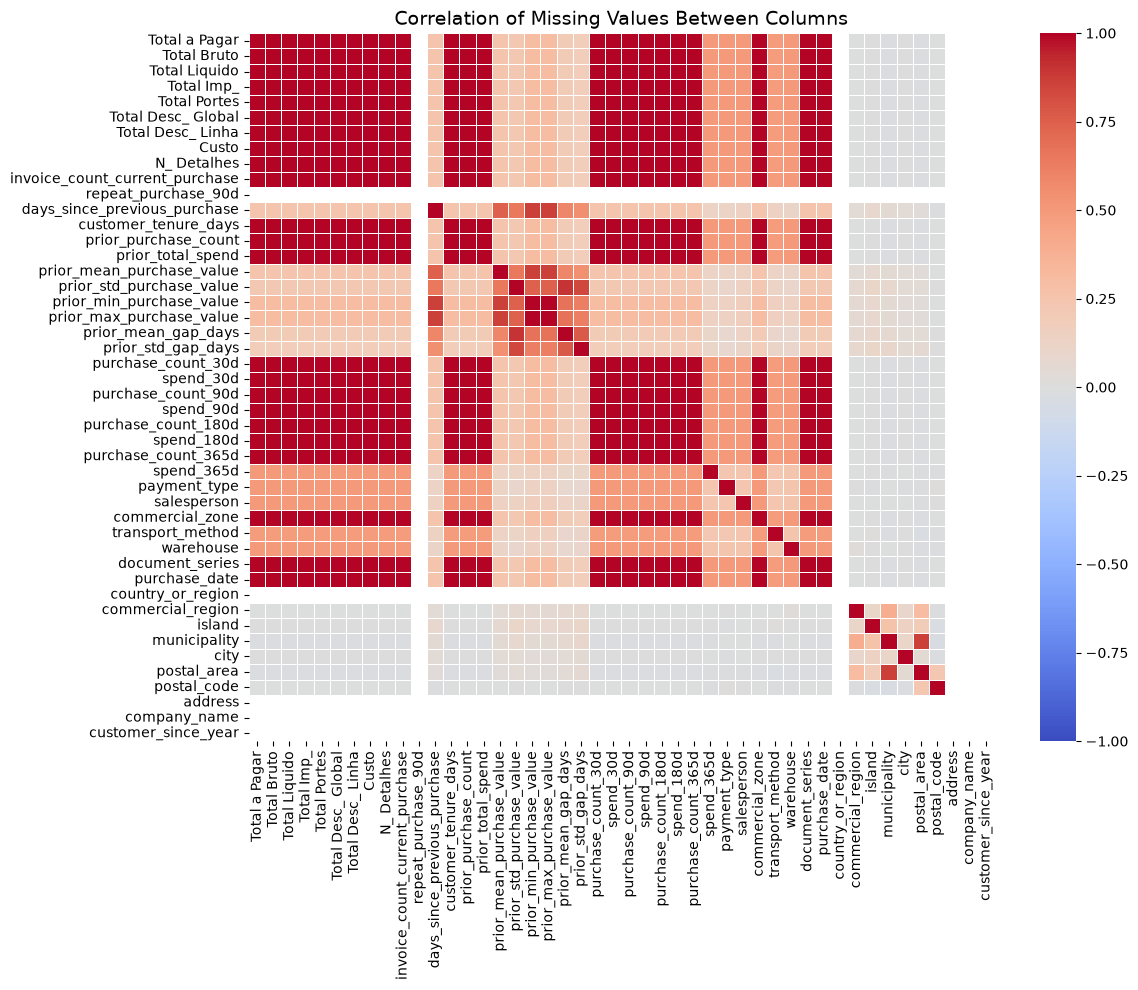

In [260]:
# Correlation of missingness
plt.figure(figsize=(12, 10))
missing_corr = train.isna().corr()

sns.heatmap(missing_corr, annot=False, cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation of Missing Values Between Columns", fontsize=14)
plt.tight_layout()
plt.show()

In [261]:
# Drop all rows where 'Total a Pagar' is missing
train = train.dropna(subset=['Total a Pagar'])
print(train.isna().sum())


Total a Pagar                        0
Total Bruto                          0
Total Liquido                        0
Total Imp_                           0
Total Portes                         0
Total Desc_ Global                   0
Total Desc_ Linha                    0
Custo                                0
N_ Detalhes                          0
invoice_count_current_purchase       0
repeat_purchase_90d                  0
days_since_previous_purchase       796
customer_tenure_days                 0
prior_purchase_count                 0
prior_total_spend                    0
prior_mean_purchase_value          797
prior_std_purchase_value          1048
prior_min_purchase_value           603
prior_max_purchase_value           603
prior_mean_gap_days               1243
prior_std_gap_days                1413
purchase_count_30d                   0
spend_30d                            0
purchase_count_90d                   0
spend_90d                            0
purchase_count_180d      

High missingness correlation across 23 features: these values aren't imputable nor synthesizable.

### Removing implausible rows

In [262]:
# Rows where the mean is impossibly greater than the total spend, etc.
corrupted_prior = train[train["prior_mean_purchase_value"] > train["prior_total_spend"]].index

corrupted_spend_365d = train[train["spend_365d"] > train["prior_total_spend"]]["spend_365d"].index
corrupted_purchase_count_180d = train[train["spend_180d"] > train["spend_365d"]]["spend_180d"].index
corrupted_purchase_count_90d = train[train["spend_90d"] > train["spend_180d"]]["spend_90d"].index
corrupted_prior_max_purchase_value = train[train["prior_max_purchase_value"] > train["prior_total_spend"]]["prior_max_purchase_value"].index
corrupted_prior_mean_purchase_value = train[train["prior_mean_purchase_value"] < 0]["prior_mean_purchase_value"].index

# Show all columns to identify the anomaly
pd.set_option('display.max_columns', None)
all_corrupted_index = (
    corrupted_prior.union(corrupted_spend_365d)
    .union(corrupted_purchase_count_180d)
    .union(corrupted_purchase_count_90d)
    .union(corrupted_prior_max_purchase_value)
    .union(corrupted_prior_mean_purchase_value)
    .union(heavy_missing_rows.index)
    .intersection(train.index)  # avoid error from dropping already-dropped rows
)
train.loc[all_corrupted_index]

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,repeat_purchase_90d,days_since_previous_purchase,customer_tenure_days,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_mean_gap_days,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,country_or_region,commercial_region,island,municipality,city,postal_area,postal_code,address,company_name,customer_since_year
8,962.63,786.27,782.63,180.00,0.0,0.0,3.64,496.926279,46.0,1.0,0,223.0,742.0,8.0,12487.24,1560.905000,1035.729065,130.18,3356.83000,74.142857,57.831446,0.0,0.00,0.0,0.00,0.0,0.00,3.0,53906.674517,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 40,Final Excel Warehouse 1,Ctrl Z Series 3,2017-11-11,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS3: The Pivot Archipelago,Municipality MU13: Council of Last Minute Edits,City CY164: Filtered View Bay,Postal area PA264: Hidden Sheet Sector,Postal code PC719: #REF! Delivery Route,Address AD417: Cell Without a Home,Excel Is Not A Database Ltd 917,2015
14,2460.00,2000.00,2000.00,460.00,0.0,0.0,0.00,0.000000,1.0,1.0,1,49.0,1277.0,31.0,3414.56,-110.147097,124.138784,0.93,552.37000,40.933333,51.012462,0.0,0.00,3.0,194.64,6.0,535.93,13.0,1019.820000,Maybe Tomorrow Payment 12,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 22,Final Excel Warehouse 1,Ctrl Z Series 2,2021-09-24,Country CT10: Land of The Final Version,Region RG27: We Will See Later,NaN,Municipality MU108: Council of Last Minute Edits,NaN,Postal area PA85: Hidden Sheet Sector,Postal code PC211: #REF! Delivery Route,Address AD807: Cell Without a Home,Excel Is Not A Database Ltd 623,2017
24,2430.26,2404.29,1975.82,454.44,0.0,0.0,428.47,584.657046,65.0,1.0,1,41.0,220.0,6.0,5520.15,920.025000,859.127283,128.78,2456.68000,NaN,27.770488,0.0,0.00,2.0,1509.54,4.0,4095.00,6.0,5520.150000,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 40,Final Excel Warehouse 1,Ctrl Z Series 1,2017-11-11,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS6: The Pivot Archipelago,Municipality MU2: Council of Last Minute Edits,City CY61: Conditional Format Harbor,Postal area PA262: Hidden Sheet Sector,Postal code PC700: #REF! Delivery Route,Address AD142: Cell Without a Home,Excel Is Not A Database Ltd 21,2015
30,427.92,356.06,356.06,71.86,0.0,0.0,0.00,211.152001,26.0,1.0,0,111.0,119.0,2.0,621.11,310.555000,307.725800,92.96,528.15000,8.000000,NaN,0.0,0.00,0.0,0.00,2.0,621.11,2.0,621.110000,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 40,Final Excel Warehouse 1,Ctrl Z Series 3,2016-07-17,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS6: The Pivot Archipelago,Municipality MU2: Council of Last Minute Edits,NaN,Postal area PA262: Hidden Sheet Sector,Postal code PC700: #REF! Delivery Route,Address AD141: Cell Without a Home,Excel Is Not A Database Ltd 677,2015
42,1118.02,908.96,908.96,209.06,0.0,0.0,0.00,538.843485,17.0,1.0,1,204.0,204.0,1.0,1680.68,1680.680000,NaN,1680.68,1680.68000,NaN,NaN,0.0,0.00,0.0,0.00,0.0,0.00,1.0,1680.680000,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 1,2021-01-17,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS8: The Pivot Archipelago,Municipality MU1: Council of Last Minute Edits,City CY38: Relative Reference Borough,Postal area PA259: Hidden Sheet Sector,Postal code PC608: #REF! Delivery Route,Address AD101: Cell Without a Home,Exc

In [263]:
train = train.drop(index=all_corrupted_index)

### Post-cleaning summary, distributions and outliers

In [264]:
target = "repeat_purchase_90d"
exclude = [target, "customer_id", "ID"]

numerical_cols = (
    train.select_dtypes(include="number")
         .columns.drop(exclude, errors="ignore")
         .tolist()
)

numerical_train = train[numerical_cols]
numerical_summary = numerical_train.describe().T.rename(
    columns={"50%": "median"}
)
numerical_summary["missing"] = numerical_train.isna().sum()
numerical_summary["IQR"] = numerical_summary["75%"] - numerical_summary["25%"]
numerical_summary = numerical_summary[
    ["count", "missing", "mean", "std", "min", "25%", "median", "75%", "max", "IQR"]
]
print(numerical_summary.to_string(float_format=lambda value: f"{value:,.2f}"))

                                  count  missing      mean       std      min      25%   median       75%        max       IQR
Total a Pagar                  6,088.00        0    931.31  1,340.61     0.93   190.96   480.99  1,103.05  22,297.21    912.09
Total Bruto                    6,088.00        0    889.70  1,330.35     0.83   176.74   448.35  1,048.09  21,578.28    871.36
Total Liquido                  6,088.00        0    777.97  1,141.06     0.76   155.40   394.09    911.22  18,127.81    755.82
Total Imp_                     6,088.00        0    153.33    225.99     0.00    30.41    80.50    187.12   4,169.40    156.71
Total Portes                   6,088.00        0      1.14      5.64     0.00     0.00     0.00      0.00     181.06      0.00
Total Desc_ Global             6,088.00        0      0.36      5.22     0.00     0.00     0.00      0.00     218.49      0.00
Total Desc_ Linha              6,088.00        0    111.36    287.98     0.00     0.00    12.75     90.14   4,1

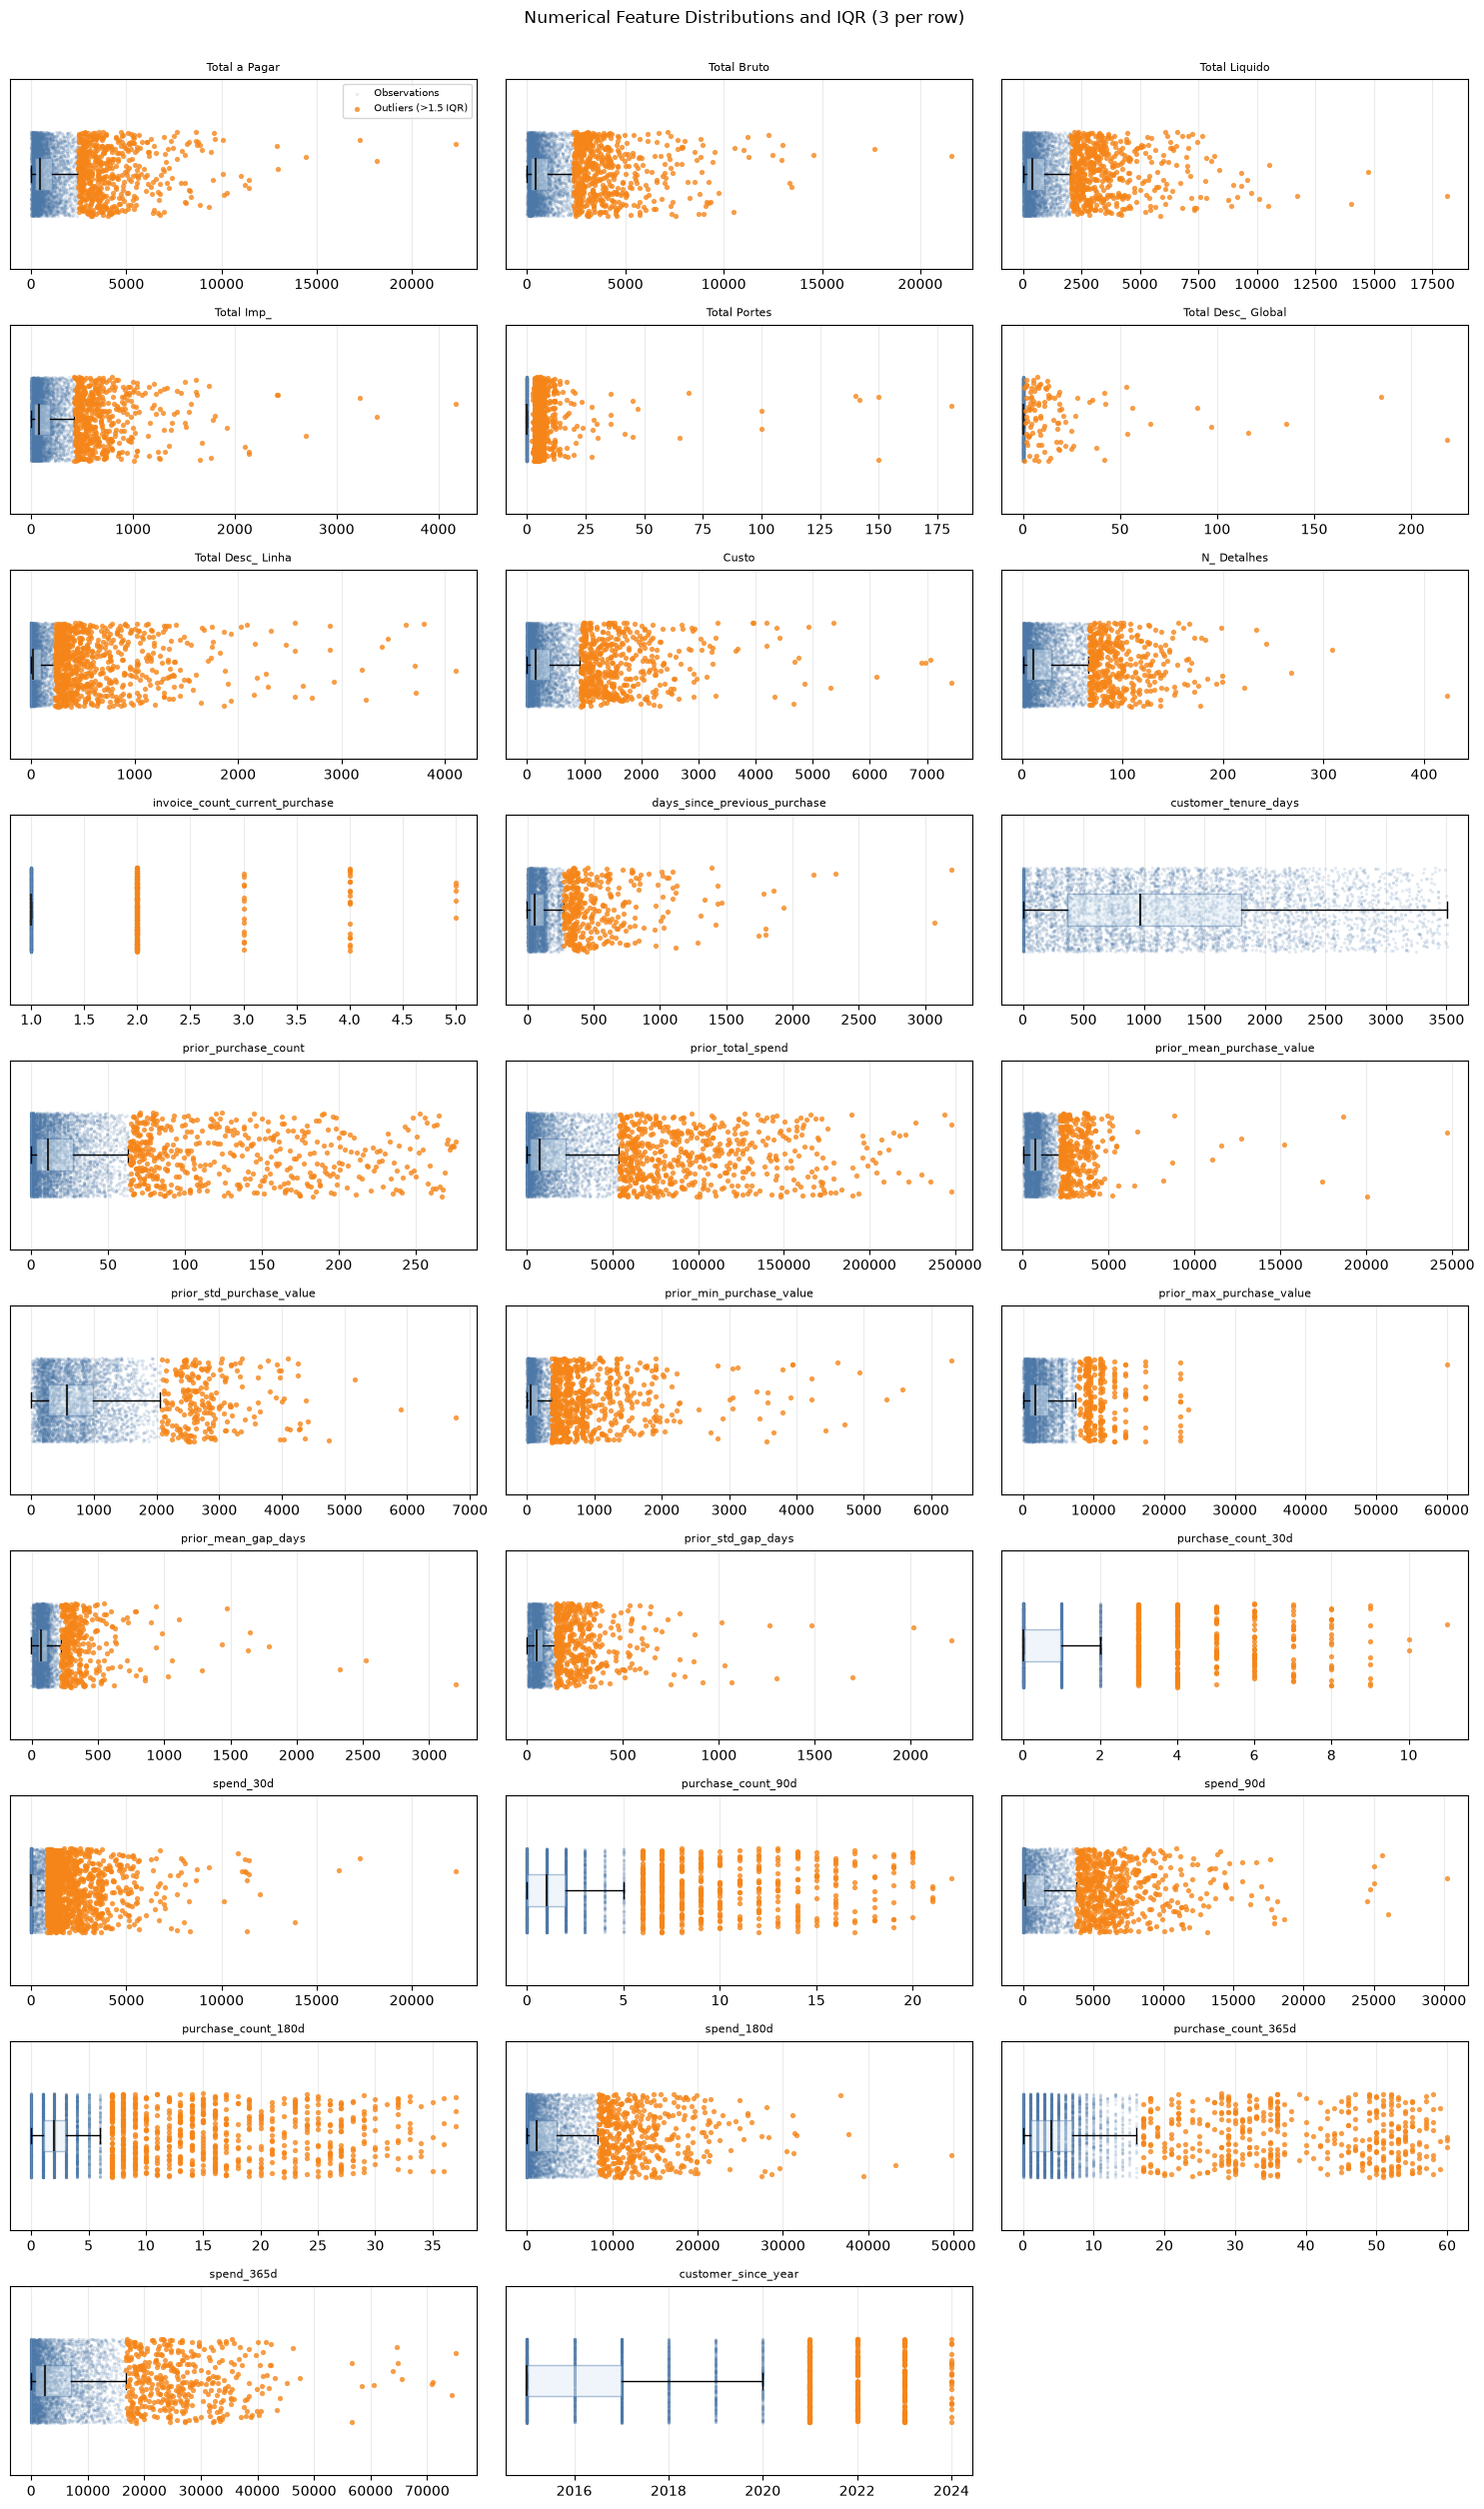

In [265]:
plot_columns = 3
plot_rows = (len(numerical_cols) + plot_columns - 1) // plot_columns
fig, axes = plt.subplots(
    plot_rows, plot_columns,
    figsize=(15, plot_rows * 2.5),
    squeeze=False,
)
rng = np.random.default_rng(42)

for feature_index, (ax, feature) in enumerate(zip(axes.flat, numerical_cols)):
    values = numerical_train[feature].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    outlier_mask = (values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)
    jitter = rng.uniform(-0.2, 0.2, size=len(values))

    ax.boxplot(
        values,
        positions=[1],
        orientation="horizontal",
        showfliers=False,
        patch_artist=True,
        boxprops={"facecolor": "#DCEAF4", "edgecolor": "#4C78A8", "alpha": 0.45},
        medianprops={"color": "#222222", "linewidth": 1.5},
    )
    ax.scatter(
        values[~outlier_mask], 1 + jitter[~outlier_mask],
        s=5, alpha=0.16, color="#4C78A8", linewidths=0,
        label="Observations" if feature_index == 0 else None,
        rasterized=True,
    )
    ax.scatter(
        values[outlier_mask], 1 + jitter[outlier_mask],
        s=14, alpha=0.8, color="#F58518", linewidths=0,
        label="Outliers (>1.5 IQR)" if feature_index == 0 else None,
        zorder=3,
    )
    ax.set_title(feature, fontsize=8)
    ax.set_yticks([])
    ax.set_ylim(0.55, 1.45)
    ax.grid(axis="x", alpha=0.25)

for ax in axes.flat[len(numerical_cols):]:
    ax.set_visible(False)

axes.flat[0].legend(loc="upper right", fontsize=7)
fig.suptitle("Numerical Feature Distributions and IQR (3 per row)", y=1.002)
fig.tight_layout()
plt.show()

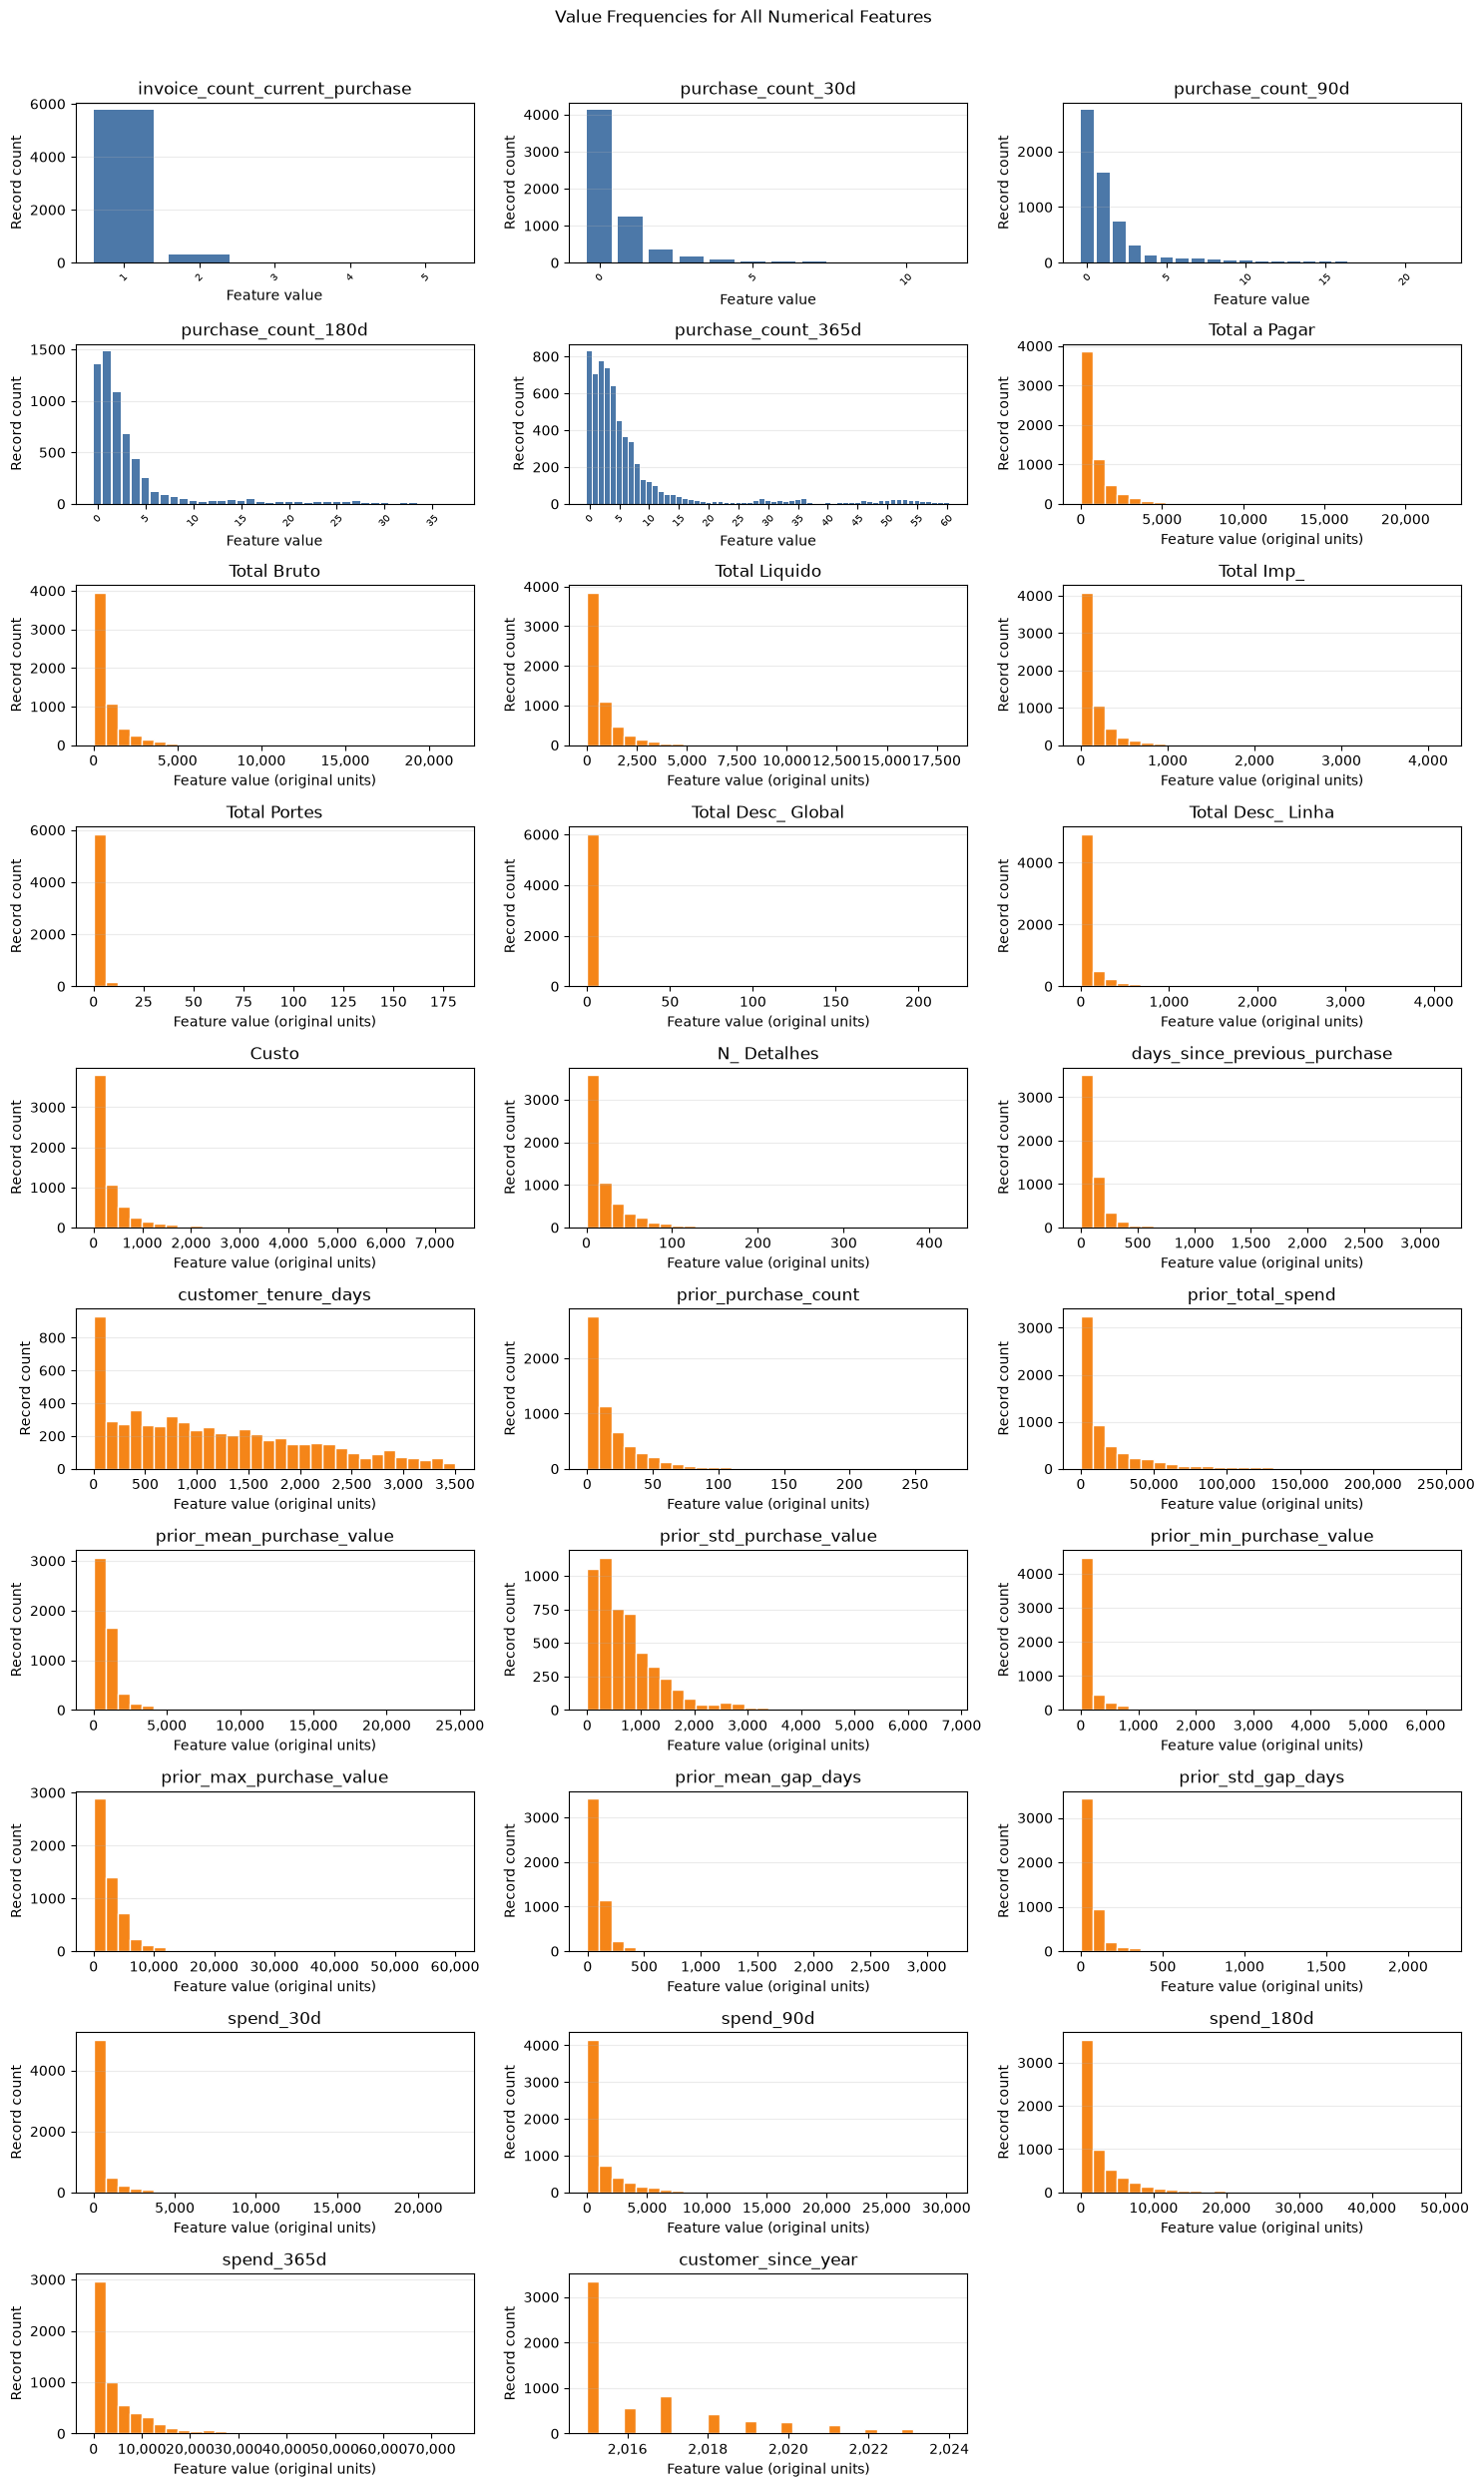

In [266]:
frequency_features = [
    feature for feature in numerical_cols
    if feature.startswith("purchase_count_")
    or feature == "invoice_count_current_purchase"
]
continuous_features = [
    feature for feature in numerical_cols if feature not in frequency_features
]
plot_features = frequency_features + continuous_features
plot_columns = 3
plot_rows = (len(plot_features) + plot_columns - 1) // plot_columns
fig, axes = plt.subplots(
    plot_rows, plot_columns,
    figsize=(15, plot_rows * 2.5),
    squeeze=False,
)

# Discrete purchase counts: one bar per observed value.
for ax, feature in zip(axes.flat, frequency_features):
    counts = numerical_train[feature].value_counts().sort_index()
    ax.bar(counts.index, counts.values, color="#4C78A8")
    ax.set_title(feature)
    ax.set_xlabel("Feature value")
    ax.set_ylabel("Record count")
    ax.set_xticks(counts.index[::5] if feature.startswith("purchase_count_") else counts.index)
    ax.tick_params(axis="x", labelrotation=45, labelsize=7)
    ax.grid(axis="y", alpha=0.25)

# Other numerical features: histogram bins show the number of records per range.
for ax, feature in zip(axes.flat[len(frequency_features):], continuous_features):
    values = numerical_train[feature].dropna()
    ax.hist(values, bins=30, color="#F58518", edgecolor="white")
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.set_title(feature)
    ax.set_xlabel("Feature value (original units)")
    ax.set_ylabel("Record count")
    ax.grid(axis="y", alpha=0.25)

for ax in axes.flat[len(plot_features):]:
    ax.set_visible(False)

fig.suptitle("Value Frequencies for All Numerical Features", y=0.995)
fig.tight_layout(rect=[0, 0, 1, 0.985])
plt.show()

**Potential data-quality issue:** some purchase-history fields contain extreme values, including values near €1 billion. These could be data-entry or processing errors and can distort summaries and model fitting. Since the target is repeat purchase within 90 days, the model should learn typical customer behavior rather than be driven by a handful of implausible records. Investigate these rows and verify their source before deciding whether to correct or exclude them.

In [267]:
outlier_counts = {}
for feature in numerical_cols:
    values = numerical_train[feature].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    outlier_mask = (values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)
    outlier_counts[feature] = int(outlier_mask.sum())

outlier_counts = pd.Series(outlier_counts, name="outlier_count").sort_values(
    ascending=False, kind="stable"
)
print(outlier_counts.to_string())

spend_30d                         1018
Total Portes                       985
Total Desc_ Linha                  774
purchase_count_180d                699
prior_min_purchase_value           645
spend_90d                          617
prior_total_spend                  582
Total Liquido                      541
Total a Pagar                      540
Total Bruto                        534
Custo                              502
Total Imp_                         499
prior_purchase_count               484
purchase_count_365d                483
spend_180d                         476
purchase_count_90d                 468
prior_std_gap_days                 440
customer_since_year                415
N_ Detalhes                        408
spend_365d                         407
purchase_count_30d                 368
prior_mean_gap_days                357
days_since_previous_purchase       354
prior_mean_purchase_value          345
invoice_count_current_purchase     331
prior_max_purchase_value 

## II.2 Imputation of remaining missing values
====missing work here=====
### **Unimputable Features**
(Rows with missing values were dropped above; no imputation fitted yet. Any imputation must be fit on the training fold only.)
Imputations for many of the features is extremely difficult, because many features are very interdependant and modifying a feature requires further modifications for all related features to avoid noise.

Ex:

Total a Pagar \& prior_mean_purchase_value \& prior_std_purchase_value

days_since_previous_purchase \& prior_mean_gap_days & prior_std_gap_days


### **Imputable Features**
Some features however can be imputable, for example, deriving the country or region using the city or postal code etc.

In [268]:
# 1. Display missing counts before imputation
cols_to_check = ['city', 'municipality', 'postal_area', 'country_or_region']
print("--- Missing Values BEFORE ---")
print(train[cols_to_check].isna().sum())
print("\n")

# 2. Define the imputation function
def impute_geography_from_peers(df):
    df_clean = df.copy()
    
    # Define mapping relationships (source_column -> target_column_to_fill)
    mapping_pairs = [
        # --- 1. Fill highly specific locations first ---
        ('postal_area', 'city'),               # if city is missing but both share the same postal_area, impute to the same city
        
        # --- 2. Fill intermediate administrative zones using the (now more complete) cities ---
        ('city', 'municipality'),              # if municipality is missing but both share the same city, impute to the same municipality
        ('postal_area', 'municipality'),       # if municipality is missing but both share the same postal_area, impute to the same municipality
        
        # --- 3. Fill the broadest regions last, leveraging all the newly filled granular data ---
        ('city', 'country_or_region'),         # if country is missing but both share the same city, impute to the same country
        ('postal_area', 'country_or_region'),  # if country is missing but both share the same postal_area, impute to the same country
        ('municipality', 'country_or_region')  # if country is missing but both share the same municipality, impute to the same country
    ]
    
    for source_col, target_col in mapping_pairs:
        if source_col not in df_clean.columns or target_col not in df_clean.columns:
            continue
            
        missing_target = df_clean[target_col].isna()
        has_source = df_clean[source_col].notna()
        rows_to_fill = missing_target & has_source
        
        if not rows_to_fill.any():
            continue
            
        # Create lookup dictionary from rows where both columns are populated
        reference_data = df_clean.dropna(subset=[source_col, target_col])
        lookup_dict = reference_data.groupby(source_col)[target_col].first().to_dict()
        
        # Map the learned values to the missing rows
        df_clean.loc[rows_to_fill, target_col] = df_clean.loc[rows_to_fill, source_col].map(lookup_dict)
        
    return df_clean

# 3. Apply the function to the dataframe
train = impute_geography_from_peers(train)

# 4. Display missing counts after imputation to verify
print("--- Missing Values AFTER ---")
print(f"{train[cols_to_check].isna().sum()}\n if values are the same, restart the notebook")


--- Missing Values BEFORE ---
city                 1998
municipality          198
postal_area           256
country_or_region       0
dtype: int64


--- Missing Values AFTER ---
city                 361
municipality         195
postal_area          256
country_or_region      0
dtype: int64
 if values are the same, restart the notebook


Even tho we have fixed Country_or_region Feature, its value imbalance is too high to give us meaning

In [269]:
train[train["city"].isna()][cols_to_check]

,city,municipality,postal_area,country_or_region
28,NaN,Municipality MU122: Council of Last Minute Edits,Postal area PA236: Hidden Sheet Sector,Country CT10: Land of The Final Version
46,NaN,Municipality MU31: Council of Last Minute Edits,Postal area PA121: Hidden Sheet Sector,Country CT10: Land of The Final Version
136,NaN,Municipality MU105: Council of Last Minute Edits,Postal area PA30: Hidden Sheet Sector,Country CT10: Land of The Final Version
152,NaN,Municipality MU69: Council of Last Minute Edits,Postal area PA89: Hidden Sheet Sector,Country CT10: Land of The Final Version
153,NaN,Municipality MU31: Council of Last Minute Edits,Postal area PA121: Hidden Sheet Sector,Country CT10: Land of The Final Version
...,...,...,...,...
6414,NaN,NaN,NaN,Country CT5: Land of The Final Version
6453,NaN,Municipality MU31: Council of Last Minute Edits,Postal area PA121: Hidden Sheet Sector,Country CT10: Land of The Final Version
6466,NaN,NaN,NaN,Country CT5: Land of The Final Version
6475,NaN,Municipality MU147: Council of Last Minute Edits,Postal area PA14: Hidden Sheet Sector,Country CT10: Land of The Final Version


## II.3 Categorical Encoding
Encode payment, salesperson, zone, transport, and warehouse.

====missing work here=====

## II.4 Feature Engineering
Derive new temporal or interaction features from purchase dates, historical gaps, and the random noise field.

====missing work here=====

## II.5 Scaling & Leakage Prevention
Fit all preprocessing (scaling, imputation, encoding) strictly on the training fold and apply to validation/test sets.

====missing work here=====

---
# III. Feature Selection Execution
## III.1 Filter Methods (Statistical Evaluation)
### Numerical vs. Numerical: Spearman (monotonic)
Checks monotonic correlation between features and with the label.

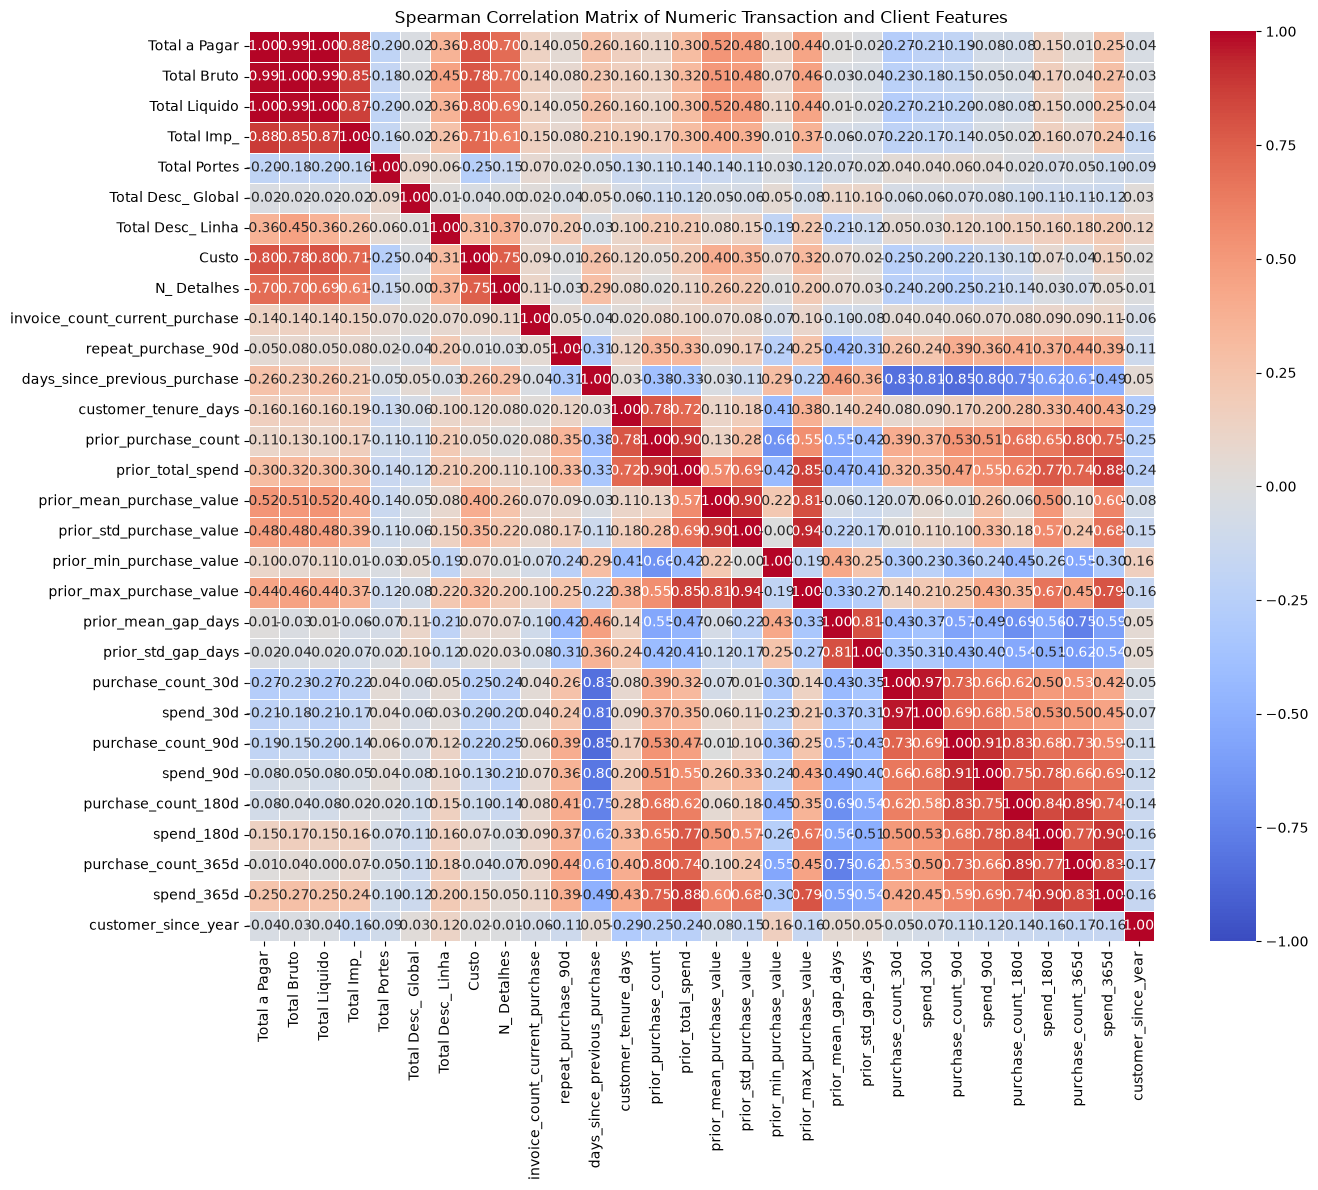

repeat_purchase_90d               1.000000
purchase_count_365d               0.437110
purchase_count_180d               0.405680
purchase_count_90d                0.392848
spend_365d                        0.390154
spend_180d                        0.371107
spend_90d                         0.361080
prior_purchase_count              0.348184
prior_total_spend                 0.333357
purchase_count_30d                0.261331
prior_max_purchase_value          0.253881
spend_30d                         0.237279
Total Desc_ Linha                 0.195887
prior_std_purchase_value          0.168845
customer_tenure_days              0.121877
prior_mean_purchase_value         0.089556
Total Imp_                        0.076295
Total Bruto                       0.076001
Total a Pagar                     0.050589
invoice_count_current_purchase    0.049312
Total Liquido                     0.047707
Total Portes                      0.019624
Custo                            -0.014713
N_ Detalhes

In [270]:
numeric_features = train.select_dtypes(include="number")
numeric_features = numeric_features.loc[
    :, numeric_features.nunique(dropna=True) > 1
]
corr_matrix = numeric_features.corr(method='spearman')

plt.figure(figsize=(14, 12))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Spearman Correlation Matrix of Numeric Transaction and Client Features")
plt.tight_layout()
plt.show()

print(corr_matrix["repeat_purchase_90d"].sort_values(ascending=False))

### Numerical vs. Numerical: Pearson (linear)

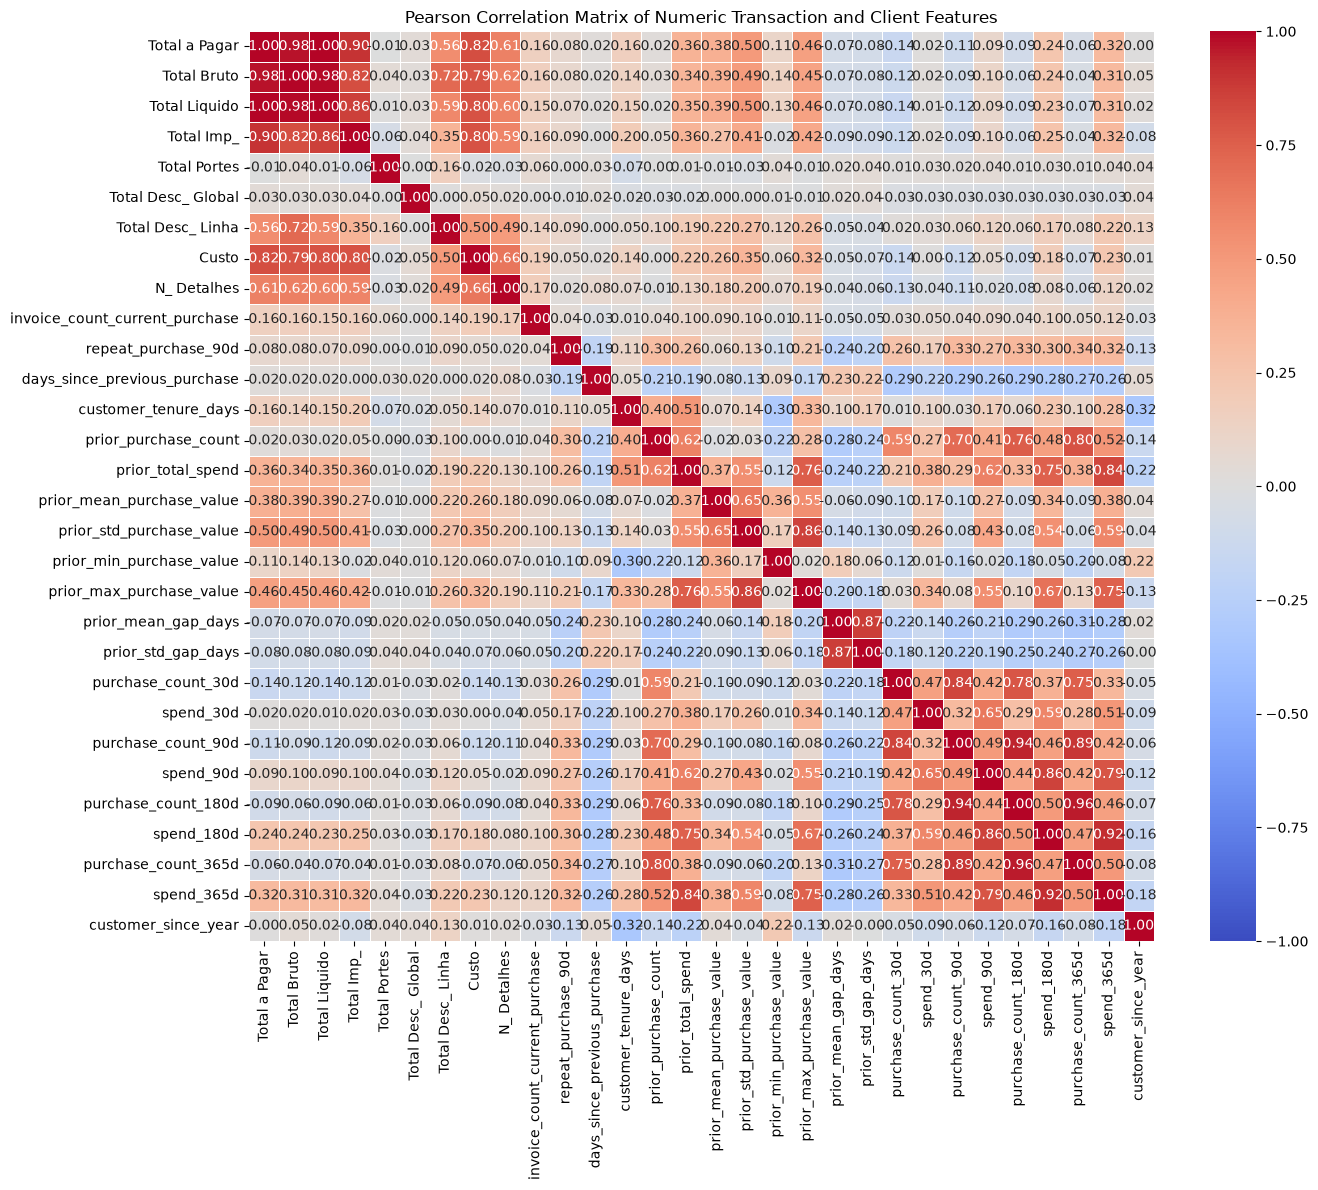

repeat_purchase_90d               1.000000
purchase_count_365d               0.339748
purchase_count_180d               0.332870
purchase_count_90d                0.326080
spend_365d                        0.320775
spend_180d                        0.300954
prior_purchase_count              0.300746
spend_90d                         0.267552
prior_total_spend                 0.263072
purchase_count_30d                0.260840
prior_max_purchase_value          0.205338
spend_30d                         0.166326
prior_std_purchase_value          0.133156
customer_tenure_days              0.109443
Total Desc_ Linha                 0.094782
Total Imp_                        0.090242
Total Bruto                       0.080787
Total a Pagar                     0.075075
Total Liquido                     0.070332
prior_mean_purchase_value         0.060792
Custo                             0.047481
invoice_count_current_purchase    0.040670
N_ Detalhes                       0.023110
Total Porte

In [271]:
corr_matrix = numeric_features.corr(method="pearson")
plt.figure(figsize=(14, 12))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Pearson Correlation Matrix of Numeric Transaction and Client Features")
plt.tight_layout()
plt.show()

print(corr_matrix["repeat_purchase_90d"].sort_values(ascending=False))

Indications show some features have no correlation to any feature nor the label in both test including pearson and spearman, this gives insights on the first features to be discarded

### Numerical vs. Categorical: ANOVA
====missing work here=====

### Categorical vs. Categorical: Chi-Squared and Mutual Information / MIC
====missing work here=====

## III.2 Wrapper Methods (Search Optimization)
Recursive Feature Elimination (RFE), wrapped inside a 10-fold cross-validation loop to prevent selection bias.

====missing work here=====

## III.3 Embedded Methods (Penalization)
LASSO (L1) and Ridge (L2) regularization.

====missing work here=====

## III.4 Exclusions
Identifier-like variables (`ID`, `customer_id`) and `random_noise` were removed in Section II.1 (`columns_to_drop`), along with `customer_type` and `street` for excessive missingness. `commercial_zone` and `warehouse` are flagged as candidates for removal (near-constant).

====missing work here===== (final decision on `commercial_zone` / `warehouse`)

---
# IV. Model Selection & Assessment Strategy
## IV.1 Candidate Generation (Tribes)
Decision Trees / Random Forests, SVM, kNN, Naive Bayes, MLP.

====missing work here=====

## IV.2 Resampling Method
Stratified 10-fold CV; nested CV if tuning hyperparameters.

====missing work here=====

## IV.3 Classification Metrics
Precision, Recall, F1, Balanced Accuracy, ROC-AUC, PR-AUC.

====missing work here=====

## IV.4 Threshold Tuning
Precision-Recall curves to choose the probability cutoff.

====missing work here=====

## IV.5 Statistical Significance
Paired / resampled t-test on CV folds, or McNemar's test on a single hold-out.

====missing work here=====

---
# V. Final Output & Deliverables
## V.1 Kaggle Submission
Predictions for the 986 observations in `test.csv`, without altering the ID column, formatted identically to `sample_submission.csv`.

====missing work here=====

## V.2 Deliverable 2: 2-page PDF
Pipeline schematic plus justification of feature selection, evaluation metrics, and preprocessing.

====missing work here=====